# D — Quantization & ESP32-S3 Static Deployment: từ 24 checkpoint đến C4/QAT/s44

Notebook nối tiếp bước C, kế thừa **8 Front-End × 3 seed = 24 checkpoint FP32**, được lượng tử bằng **PTQ INT8, QAT INT8 và PTQ INT16x8** (72 phiên bản). Mục tiêu gồm hai phần nối tiếp:

1. **Quantization (D0–D13):** kiểm toán dữ liệu/recipe, so sánh Validation, historical Test, Accuracy, Macro F1, Asthma Recall, FN/FP, độ biến thiên theo seed, kích thước và phép đối chứng có/không pre-emphasis. Giữ toàn bộ bảng và biểu đồ thí nghiệm.
2. **Static Deployment (D14):** đối chiếu **ba checkpoint đã đo thực tế** trên ESP32-S3: `F0/s43/PTQ` (baseline lịch sử), `C3/s44/QAT` (bật pre, cùng Mel/FFT với C4) và **`C4/s44/QAT`** (tắt pre, model nguyên mẫu). Phân tích dung lượng file, TensorArena, `Invoke()`, parity và mức ổn định; không mở thêm vòng profiling.

**Phạm vi quyết định:** ưu tiên **V1 / C4 / seed 44 / QAT INT8** cho nguyên mẫu. D **không khảo sát lại thứ hạng V1–V6**; phép kiểm chứng kiến trúc V1–V3 ở pipeline C4 thuộc notebook kiểm chứng cuối `C_Extend`. `PTQ_INT16x8` chỉ là đối chứng nghiên cứu, chưa được xác nhận tương thích runtime TFLM trên ESP32-S3.

> Historical Test 159 WAV đã được tham khảo nhiều lần, không còn là holdout độc lập. Kiểm thử ESP32-S3 ở D14 sử dụng **12 tensor INT8 tĩnh** (36 lượt `Invoke()` mỗi model), **không** đo thời gian thu âm, DSP hay hiệu năng trên dữ liệu bệnh nhân mới. Các thống kê này không dùng để suy ra khả năng chẩn đoán lâm sàng.


## D0 - Thiết lập và hợp đồng thí nghiệm

Cell kế tiếp tự tìm `Frontend_Benchmarking` dù notebook được mở từ root repo hay từ chính thư mục `Notebook/05_Quantization_Deployment`. Mọi hình và bảng mới được lưu vào `results/D_Quantization/Full_24_Analysis/`.

In [17]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FRONTEND_RELATIVE = Path('Experiments_Benchmarking/Patient_Node/Frontend_Benchmarking')

def find_frontend_root():
    cwd = Path.cwd().resolve()
    candidates = []
    for base in (cwd, *cwd.parents):
        candidates.extend([base, base / FRONTEND_RELATIVE])
    seen = set()
    for candidate in candidates:
        key = str(candidate)
        if key in seen:
            continue
        seen.add(key)
        if (candidate / 'D2_Evaluate_Quantized.py').is_file() and (candidate / 'results').is_dir():
            return candidate.resolve()
    raise FileNotFoundError('Không tìm thấy Frontend_Benchmarking từ cwd: ' + str(cwd))

ROOT = find_frontend_root()
RESULTS = ROOT / 'results'
D_RESULTS = RESULTS / 'D_Quantization'
D_ARTIFACTS = ROOT / 'artifacts' / 'D_Quantization'
NOTEBOOK_DIR = ROOT / 'Notebook' / '05_Quantization_Deployment'
LOCAL_LOG_DIR = NOTEBOOK_DIR / 'log'
OUTPUT_DIR = D_RESULTS / 'Full_24_Analysis'
FIGURE_DIR = OUTPUT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

PLAN_PATH = D_RESULTS / 'quantization_plan.json'
PLAN = json.loads(PLAN_PATH.read_text(encoding='utf-8'))
TRIALS = [row['trial_id'] for row in PLAN['trials']]
QUANT_METHODS = [row['method_id'] for row in PLAN['methods']]
METHODS = ['KERAS_FP32', *QUANT_METHODS]
VARIANT_ORDER = ['F0', 'pre_0', 'mel_40', 'fft_2048',
                 'combo_pre0_mel40', 'combo_pre0_fft2048',
                 'combo_mel40_fft2048', 'combo_pre0_mel40_fft2048']
VARIANT_SHORT = {'F0':'F0', 'pre_0':'Pre0', 'mel_40':'Mel40', 'fft_2048':'FFT2048',
                 'combo_pre0_mel40':'C1', 'combo_pre0_fft2048':'C2',
                 'combo_mel40_fft2048':'C3', 'combo_pre0_mel40_fft2048':'C4'}
METHOD_COLORS = {'KERAS_FP32':'#64748b', 'PTQ_INT8':'#2563eb',
                 'QAT_INT8':'#10b981', 'PTQ_INT16x8':'#f59e0b'}

def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def save_show(fig, name):
    path = FIGURE_DIR / name
    fig.savefig(path, dpi=180, bbox_inches='tight', facecolor='white')
    display(fig)
    plt.close(fig)
    print('Đã lưu:', path)

plt.rcParams.update({'figure.facecolor':'white', 'axes.facecolor':'#fbfdff',
                     'axes.grid':True, 'grid.alpha':0.18, 'font.size':10})
print('Frontend root :', ROOT)
print('Plan SHA256   :', PLAN['plan_sha256'])
print('Checkpoint    :', len(TRIALS))
print('Quant methods :', QUANT_METHODS)
print('Output        :', OUTPUT_DIR)
print('ESP32 logs    :', LOCAL_LOG_DIR)

Frontend root : D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking
Plan SHA256   : 8258e0c64948a6d2916f84089bd590f40c8b026b22f713e5bfe1845dabbe544d
Checkpoint    : 24
Quant methods : ['PTQ_INT8', 'QAT_INT8', 'PTQ_INT16x8']
Output        : D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis
ESP32 logs    : D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\Notebook\05_Quantization_Deployment\log


### Lý thuyết trung về 2 phương pháp lượng tử

| Tiêu chí | PTQ | QAT |
|---|---|---|
| Tên đầy đủ | Post-Training Quantization | Quantization-Aware Training |
| Thời điểm | Sau huấn luyện | Trong huấn luyện/tinh chỉnh |
| Có cập nhật trọng số ? | Không | Có |
| Cách hoạt động | Chuyển FP32 sang INT8, hiệu chuẩn dải giá trị | Mô phỏng sai số INT8 khi huấn luyện |
| Ưu | Nhanh, đơn giản | Có khả năng thích nghi với sai số lượng tử |
| Nhược | Có thể giảm Accuracy/Recall | Tốn công huấn luyện |

PTQ giữ nguyên trọng số đã học về mặt giá trị gốc, rồi ánh xạ chúng về biểu diễn số nguyên có độ chính xác thấp hơn
> Do sai số làm tròn, đầu ra của mạng có thể thay đổi. PTQ không huấn luyện lại để sửa những thay đổi đó.

QAT đưa sai số lượng tử hóa vào quá trình huấn luyện. Mô hình học cách điều chỉnh trọng số để giảm tác động của sai số đó
> **Điểm quan trọng:** Trong QAT thông thường, trọng số vẫn được tối ưu bằng số thực trong khi mô phỏng phép lượng tử hóa, không phải toàn bộ quá trình huấn luyện đều thực hiện bằng INT8.

## D1 - Nạp dữ liệu C và D, kiểm tra tính toàn vẹn

Điều kiện PASS:

- plan có đúng 24 checkpoint, tám variant và ba seed;
- mỗi split có đủ 24 × 4 phiên bản;
- mỗi phiên bản có cùng tập WAV và nhãn;
- Keras FP32 trong D khớp tuyệt đối model SHA và Accuracy đã đăng ký tại C;
- mọi dòng D mang đúng Plan SHA hiện hành.

In [18]:
assert len(TRIALS) == 24 and len(set(TRIALS)) == 24, 'Plan D không có đúng 24 checkpoint'
plan_meta = pd.DataFrame(PLAN['trials'])[['trial_id','variant_id','seed','config_sha256','model_sha256']]
assert set(plan_meta.variant_id) == set(VARIANT_ORDER)
assert set(plan_meta.seed.astype(int)) == {42, 43, 44}
assert plan_meta.groupby('variant_id').seed.nunique().eq(3).all()

C = {}
D_SUMMARY = {}
PRED = {}
for split, folder, summary_name, prediction_name, expected_wav in [
    ('val', 'Validation', 'validation_summary.csv', 'Validation_All_Models_Predictions.csv', 154),
    ('test', 'Test', 'test_summary.csv', 'Test_All_Models_Predictions.csv', 159),
]:
    c = pd.read_csv(RESULTS / f'{split}_summary.csv')
    c = c[c.trial_id.isin(TRIALS)].copy()
    assert len(c) == 24 and not c.trial_id.duplicated().any()
    C[split] = c

    d = pd.read_csv(D_RESULTS / folder / summary_name)
    assert len(d) == 24 * 4
    assert set(d.trial_id) == set(TRIALS) and set(d.method_id) == set(METHODS)
    assert set(d.plan_sha256) == {PLAN['plan_sha256']}
    assert not d.duplicated(['trial_id','method_id']).any()
    D_SUMMARY[split] = d

    pred = pd.read_csv(D_ARTIFACTS / 'Combined_Evaluation' / prediction_name)
    assert len(pred) == expected_wav * 24 * 4
    assert set(pred.trial_id) == set(TRIALS) and set(pred.method_id) == set(METHODS)
    assert not pred.duplicated(['trial_id','method_id','file']).any()
    counts = pred.groupby(['trial_id','method_id']).size()
    assert counts.eq(expected_wav).all()
    assert pred.p_non_asthma.between(0, 1).all()
    assert (pred.predicted_label.astype(int) == pred.p_non_asthma.ge(.5).astype(int)).all()
    PRED[split] = pred

    fp = d[d.method_id.eq('KERAS_FP32')]
    check = c.merge(fp, on='trial_id', suffixes=('_C','_D'), validate='one_to_one')
    assert (check.model_sha256_C == check.model_sha256_D).all()
    assert np.allclose(check.accuracy_C, check.accuracy_D, atol=1e-12, rtol=0)
    print(f'{split.upper()}: PASS | summary={len(d)} | prediction={len(pred):,} | WAV/model={expected_wav}')

display(plan_meta.sort_values(['variant_id','seed']).reset_index(drop=True))

VAL: PASS | summary=96 | prediction=14,784 | WAV/model=154
TEST: PASS | summary=96 | prediction=15,264 | WAV/model=159


,trial_id,variant_id,seed,config_sha256,model_sha256
0,F0__V1__s42,F0,42,ee7d6a78c90c0dbee4ca32dd1d4690b3af5721a3d8044b...,3dabdca006822e0ea7bdc6f975ea7d290b49e74053599e...
1,F0__V1__s43,F0,43,ee7d6a78c90c0dbee4ca32dd1d4690b3af5721a3d8044b...,b0733dba5a0a81fcecb67745f06424e6ce4af5ab0bba17...
2,F0__V1__s44,F0,44,ee7d6a78c90c0dbee4ca32dd1d4690b3af5721a3d8044b...,7bf75bf43b26fe2f1cc8dd68feab7f05101d0746def8d1...
3,combo_mel40_fft2048__V1__s42,combo_mel40_fft2048,42,767ada98eba6b1f0bef5196a3c61200c7909a707a84f03...,bd3d5ac40dc67af8d89bcb6619e51db05af9c94545b9ef...
4,combo_mel40_fft2048__V1__s43,combo_mel40_fft2048,43,767ada98eba6b1f0bef5196a3c61200c7909a707a84f03...,cf4a51f6c6457755cab82559c25b5139fed80c1cfb4b84...
5,combo_mel40_fft2048__V1__s44,combo_mel40_fft2048,44,767ada98eba6b1f0bef5196a3c61200c7909a707a84f03...,55028fe6f65fb2c2e716ca22149e8815f701d3467e6804...
6,combo_pre0_fft2048__V1__s42,combo_pre0_fft2048,42,06ebc4a5131e455dcda52177ec80d5c4dc56ab117f4569...,2a6f179cf9aaa94028c4ce0b0fc504080c392cee948ee4...
7,combo_pre0_fft2048__V1__s43,combo_pre0_fft2048,43,06ebc4a5131e455dcda52177ec80d5c4dc56ab117f4569...,4fbd07d221e341e0d386e419abc8913d14721df6746a5b...
8,combo_pre0_fft2048__V1__s44,combo_pre0_fft2048,44,06ebc4a5131e455dcda52177ec80d5c4dc56ab117f4569...,b70458c565cf1a09559229aa4cec0a8e7c08ca4d8a2c66...
9,combo_pre0_mel40__V1__s42,combo_pre0_mel40,42,2061cea281c95fb43b56f0b4dec849b80c78d5c1741437...,b2265c23306ccbc9cfc8102a3dc51c3f04bd0480bcfd28...


## D2 - Kế thừa kết quả C: FP32 Validation so với Test

Biểu đồ dumbbell dùng Accuracy trung bình ba seed của từng cấu hình. Khoảng cách Val → Test phản ánh generalization gap quan sát trên historical Test, không phải độ chắc chắn thống kê ngoài tập dữ liệu hiện tại.

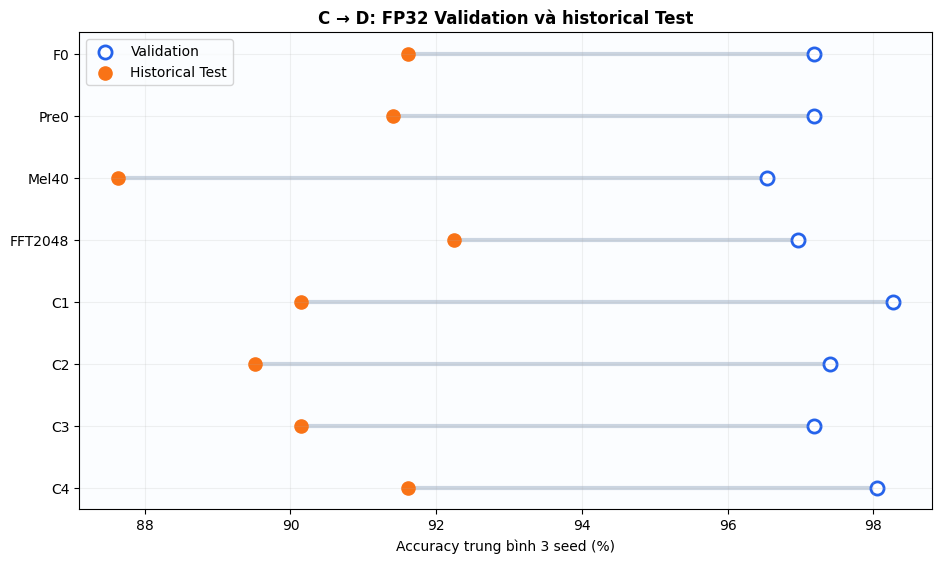

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\01_C_FP32_Val_vs_Test.png


,split,variant_id,accuracy_mean,accuracy_std,macro_f1_mean,asthma_recall_mean
0,test,F0,91.614,2.542,0.892,0.921
1,test,combo_mel40_fft2048,90.147,0.726,0.872,0.886
2,test,combo_pre0_fft2048,89.518,2.542,0.868,0.912
3,test,combo_pre0_mel40,90.147,1.309,0.872,0.886
4,test,combo_pre0_mel40_fft2048,91.614,1.309,0.887,0.860
5,test,fft_2048,92.243,2.209,0.899,0.912
6,test,mel_40,87.631,4.188,0.844,0.868
7,test,pre_0,91.405,0.363,0.889,0.912
8,val,F0,97.186,2.928,0.964,0.982
9,val,combo_mel40_fft2048,97.186,0.992,0.964,1.000


In [19]:
c_all = pd.concat([df.assign(split=split) for split, df in C.items()], ignore_index=True)
c_seed = c_all.groupby(['split','variant_id']).agg(
    accuracy_mean=('accuracy','mean'), accuracy_std=('accuracy','std'),
    macro_f1_mean=('macro_f1','mean'), asthma_recall_mean=('asthma_recall','mean')
).reset_index()
c_pivot = c_seed.pivot(index='variant_id', columns='split', values='accuracy_mean').reindex(VARIANT_ORDER)
fig, ax = plt.subplots(figsize=(11, 6.2))
y = np.arange(len(c_pivot))
for i, (variant, row) in enumerate(c_pivot.iterrows()):
    ax.plot([row['val']*100, row['test']*100], [i,i], color='#cbd5e1', lw=3, zorder=1)
ax.scatter(c_pivot['val']*100, y, s=90, facecolor='white', edgecolor='#2563eb', lw=2, label='Validation')
ax.scatter(c_pivot['test']*100, y, s=90, color='#f97316', label='Historical Test')
ax.set_yticks(y, [VARIANT_SHORT[v] for v in c_pivot.index])
ax.set_xlabel('Accuracy trung bình 3 seed (%)')
ax.set_title('C → D: FP32 Validation và historical Test', weight='bold')
ax.legend(); ax.invert_yaxis()
save_show(fig, '01_C_FP32_Val_vs_Test.png')
display((c_seed.assign(accuracy_mean=lambda x:x.accuracy_mean*100,
                       accuracy_std=lambda x:x.accuracy_std*100)).round(3))

## D3 - Tổng quan bốn phiên bản: FP32 và ba phương pháp lượng tử

Bảng và biểu đồ sau lấy trung bình trên đủ 24 checkpoint. Đây là góc nhìn toàn cục; các mục sau sẽ tách variant và seed để tránh che khuất trường hợp bất lợi.

,split,method_id,accuracy_mean,accuracy_std,macro_f1_mean,asthma_recall_mean,asthma_fn_mean,non_asthma_fp_mean,size_mean_kib
0,test,KERAS_FP32,90.540,2.342,87.786,89.474,4.000,11.042,5100.600
1,test,PTQ_INT16x8,90.618,2.194,87.884,89.693,3.917,11.000,438.906
2,test,PTQ_INT8,91.116,2.552,87.540,80.592,7.375,6.750,435.227
3,test,QAT_INT8,91.536,2.065,88.886,89.035,4.167,9.292,435.810
4,val,KERAS_FP32,97.348,1.353,96.547,98.794,0.458,3.625,5100.600
5,val,PTQ_INT16x8,97.376,1.374,96.575,98.684,0.500,3.542,438.906
6,val,PTQ_INT8,95.482,3.049,93.636,88.048,4.542,2.417,435.227
7,val,QAT_INT8,97.240,1.087,96.356,97.259,1.042,3.208,435.810


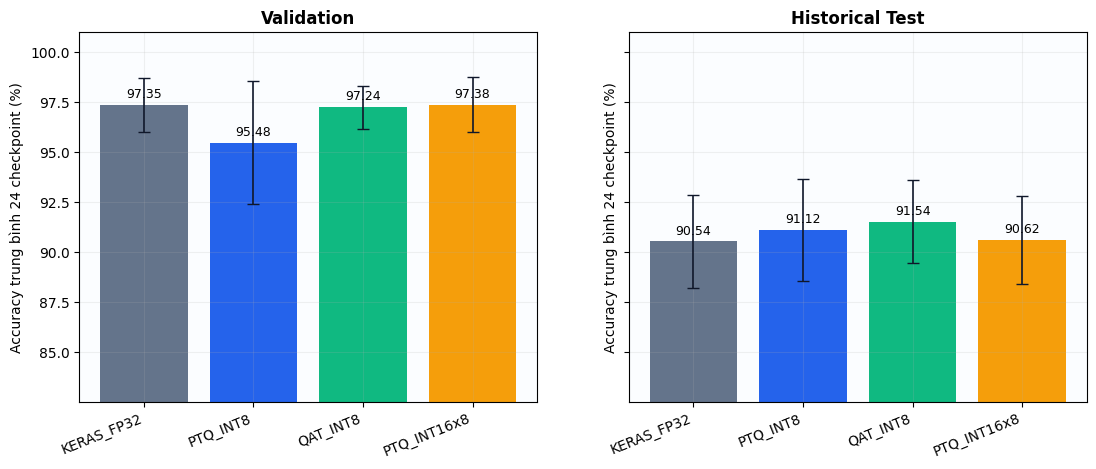

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\02_Method_Overview_24_Checkpoints.png


In [20]:
d_all = pd.concat([df.assign(split=split) for split, df in D_SUMMARY.items()], ignore_index=True)
overview = d_all.groupby(['split','method_id']).agg(
    accuracy_mean=('accuracy','mean'), accuracy_std=('accuracy','std'),
    macro_f1_mean=('macro_f1','mean'), asthma_recall_mean=('asthma_recall','mean'),
    asthma_fn_mean=('asthma_fn','mean'), non_asthma_fp_mean=('non_asthma_fp','mean'),
    size_mean=('model_size_bytes','mean')
).reset_index()
display(overview.assign(
    accuracy_mean=lambda x:x.accuracy_mean*100, accuracy_std=lambda x:x.accuracy_std*100,
    macro_f1_mean=lambda x:x.macro_f1_mean*100, asthma_recall_mean=lambda x:x.asthma_recall_mean*100,
    size_mean_kib=lambda x:x.size_mean/1024
).drop(columns='size_mean').round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, split in zip(axes, ['val','test']):
    sub = overview[overview.split.eq(split)].set_index('method_id').reindex(METHODS)
    bars = ax.bar(np.arange(len(sub)), sub.accuracy_mean*100,
                  color=[METHOD_COLORS[m] for m in sub.index])
    ax.errorbar(np.arange(len(sub)), sub.accuracy_mean*100, yerr=sub.accuracy_std*100,
                fmt='none', color='#0f172a', capsize=4, lw=1.2)
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=9)
    ax.set_xticks(np.arange(len(sub)), sub.index, rotation=22, ha='right')
    ax.set_title('Validation' if split=='val' else 'Historical Test', weight='bold')
    ax.set_ylabel('Accuracy trung bình 24 checkpoint (%)')
    ax.set_ylim(max(0, sub.accuracy_mean.min()*100-8), 101)
save_show(fig, '02_Method_Overview_24_Checkpoints.png')

### Kết luận ngắn

Từ kết quả phân loại Test
- QAT INT8 cao hơn PTQ INT8 khoảng 0.42%
- QAT INT8 cao hơn FP32 khoảng 1%

Nhưng vấn đề quan trọng, PTQ có Accuracy khá tốt nhưng Recall Asthma lại giảm mạnh

> Đối với một hệ thống hỗ trợ cảnh báo hen suyễn, Asthma Recall và số False Negative (FN) quan trọng không kém, thậm chí cần được ưu tiên hơn Accuracy đơn thuần.


## D4 - Heatmap Accuracy của 24 checkpoint × 4 phiên bản

Mỗi hàng là một checkpoint cụ thể, không phải trung bình. Heatmap giúp nhìn nhanh model/seed nào được bảo toàn hoặc suy giảm sau lượng tử.

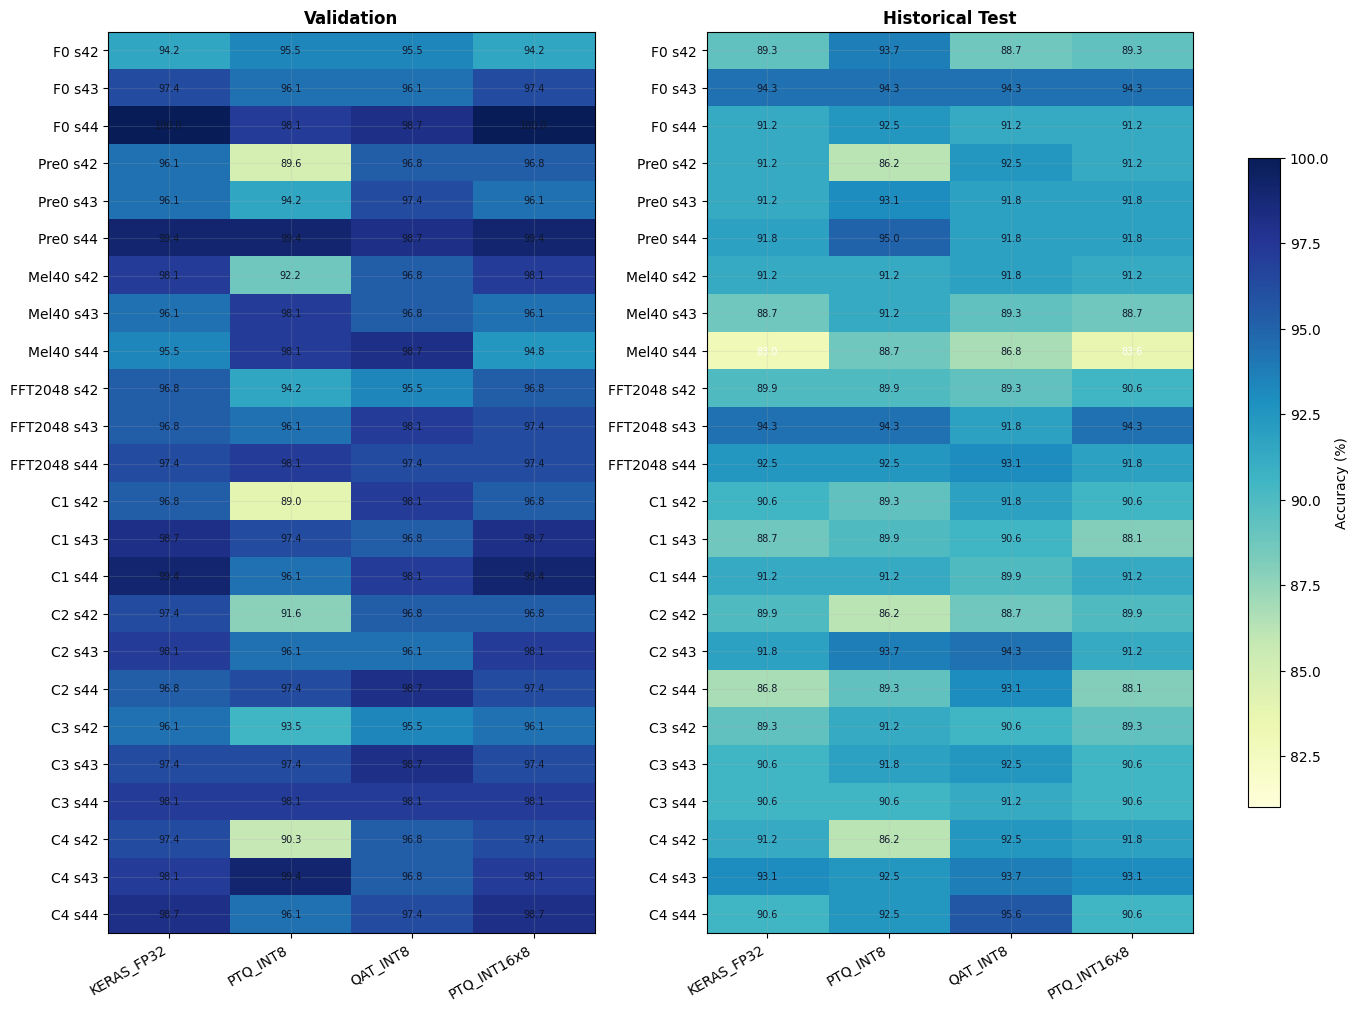

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\03_Accuracy_Heatmap_24x4.png


In [21]:
trial_order = [f'{v}__V1__s{s}' for v in VARIANT_ORDER for s in (42,43,44)]
trial_labels = [f'{VARIANT_SHORT[v]} s{s}' for v in VARIANT_ORDER for s in (42,43,44)]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 10), constrained_layout=True)
for ax, split in zip(axes, ['val','test']):
    mat = D_SUMMARY[split].pivot(index='trial_id', columns='method_id', values='accuracy').reindex(index=trial_order, columns=METHODS)*100
    im = ax.imshow(mat.to_numpy(), aspect='auto', cmap='YlGnBu', vmin=max(70, mat.min().min()-2), vmax=100)
    ax.set_xticks(range(len(METHODS)), METHODS, rotation=30, ha='right')
    ax.set_yticks(range(len(trial_labels)), trial_labels)
    ax.set_title('Validation' if split=='val' else 'Historical Test', weight='bold')
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f'{mat.iloc[i,j]:.1f}', ha='center', va='center', fontsize=7,
                    color='white' if mat.iloc[i,j] < 84 else '#0f172a')
fig.colorbar(im, ax=axes, shrink=.72, label='Accuracy (%)')
save_show(fig, '03_Accuracy_Heatmap_24x4.png')

### D4.1 - Bảng đầy đủ 72 model lượng tử trên Validation và Test

Mỗi dòng bên dưới là **một model lượng tử cụ thể**: một cấu hình frontend, một seed và một phương pháp lượng tử. Ba bảng tương ứng với `PTQ_INT8`, `QAT_INT8` và `PTQ_INT16x8`; mỗi bảng có 24 dòng, tổng cộng đúng 72 model. Các chỉ số Validation và Test được ghép cạnh nhau để không nhầm giữa hai tập.

In [22]:
DETAIL_METRICS = ['accuracy','balanced_accuracy','macro_f1',
                  'asthma_precision','asthma_recall','asthma_f1',
                  'non_asthma_precision','non_asthma_recall','non_asthma_f1',
                  'asthma_fn','non_asthma_fp']
all_long = d_all[
    ['split','trial_id','variant_id','seed','method_id'] + DETAIL_METRICS +
    ['prediction_changes_vs_fp32','mean_abs_probability_delta','model_size_bytes','model_sha256']
].copy()
quant_long = all_long[all_long.method_id.isin(QUANT_METHODS)].copy()

identity = ['trial_id','variant_id','seed','method_id']
val_detail = quant_long[quant_long.split.eq('val')].drop(columns='split').set_index(identity)
test_detail = quant_long[quant_long.split.eq('test')].drop(columns='split').set_index(identity)
quant_72 = val_detail.join(test_detail, how='inner', lsuffix='_val', rsuffix='_test').reset_index()
quant_72['variant_order'] = quant_72.variant_id.map({v:i for i,v in enumerate(VARIANT_ORDER)})
quant_72['method_order'] = quant_72.method_id.map({m:i for i,m in enumerate(QUANT_METHODS)})
quant_72 = quant_72.sort_values(['method_order','variant_order','seed']).drop(columns=['variant_order','method_order'])
assert len(quant_72) == 72, f'Bảng chi tiết phải có 72 model, hiện có {len(quant_72)}'
assert quant_72.trial_id.nunique() == 24 and quant_72.method_id.nunique() == 3

all_val = all_long[all_long.split.eq('val')].drop(columns='split').set_index(identity)
all_test = all_long[all_long.split.eq('test')].drop(columns='split').set_index(identity)
all_96 = all_val.join(all_test, how='inner', lsuffix='_val', rsuffix='_test').reset_index()
all_96['variant_order'] = all_96.variant_id.map({v:i for i,v in enumerate(VARIANT_ORDER)})
all_96['method_order'] = all_96.method_id.map({m:i for i,m in enumerate(METHODS)})
all_96 = all_96.sort_values(['variant_order','seed','method_order']).drop(columns=['variant_order','method_order'])
assert len(all_96) == 96, f'Bảng tổng hợp phải có 96 checkpoint-model, hiện có {len(all_96)}'

display_cols = ['trial_id','seed','method_id',
                'accuracy_val','accuracy_test','balanced_accuracy_val','balanced_accuracy_test',
                'macro_f1_val','macro_f1_test','asthma_precision_val','asthma_precision_test',
                'asthma_recall_val','asthma_recall_test','asthma_f1_val','asthma_f1_test',
                'non_asthma_f1_val','non_asthma_f1_test','asthma_fn_val','asthma_fn_test',
                'non_asthma_fp_val','non_asthma_fp_test']
percent_cols = [c for c in display_cols if any(k in c for k in ['accuracy','macro_f1','precision','recall','asthma_f1'])]
for method in QUANT_METHODS:
    table = quant_72[quant_72.method_id.eq(method)][display_cols].copy()
    table[percent_cols] = table[percent_cols] * 100
    display(Markdown(f'#### {method} - 24 checkpoint'))
    display(table.round(3).reset_index(drop=True))
print(f'Đã liệt kê {len(quant_72)} model lượng tử = 24 checkpoint × {len(QUANT_METHODS)} phương pháp.')

#### PTQ_INT8 - 24 checkpoint

,trial_id,seed,method_id,accuracy_val,accuracy_test,balanced_accuracy_val,balanced_accuracy_test,macro_f1_val,macro_f1_test,asthma_precision_val,...,asthma_recall_val,asthma_recall_test,asthma_f1_val,asthma_f1_test,non_asthma_f1_val,non_asthma_f1_test,asthma_fn_val,asthma_fn_test,non_asthma_fp_val,non_asthma_fp_test
0,F0__V1__s42,42,PTQ_INT8,95.455,93.711,95.213,93.160,94.041,91.649,87.805,...,94.737,92.105,91.139,87.500,96.943,95.798,2,3,5,7
1,F0__V1__s43,43,PTQ_INT8,96.104,94.340,94.760,92.671,94.760,92.289,92.105,...,92.105,89.474,92.105,88.312,97.414,96.266,3,4,3,5
2,F0__V1__s44,44,PTQ_INT8,98.052,92.453,96.937,89.626,97.356,89.626,97.297,...,94.737,84.211,96.000,84.211,98.712,95.041,2,6,1,6
3,pre_0__V1__s42,42,PTQ_INT8,89.610,86.164,80.717,74.663,84.221,77.961,92.308,...,63.158,52.632,75.000,64.516,93.443,91.406,14,18,2,4
4,pre_0__V1__s43,43,PTQ_INT8,94.156,93.082,92.582,90.942,92.208,90.575,87.179,...,89.474,86.842,88.312,85.714,96.104,95.436,4,5,5,6
5,pre_0__V1__s44,44,PTQ_INT8,99.351,94.969,99.569,93.084,99.134,93.084,97.436,...,100.000,89.474,98.701,89.474,99.567,96.694,0,4,1,4
6,mel_40__V1__s42,42,PTQ_INT8,92.208,91.195,86.865,86.092,88.908,87.432,90.625,...,76.316,76.316,82.857,80.556,94.958,94.309,9,9,3,5
7,mel_40__V1__s43,43,PTQ_INT8,98.052,91.195,97.822,86.994,97.403,87.672,94.872,...,97.368,78.947,96.104,81.081,98.701,94.262,1,8,2,6
8,mel_40__V1__s44,44,PTQ_INT8,98.052,88.679,96.053,87.147,97.307,85.211,100.000,...,92.105,84.211,95.890,78.049,98.723,92.373,3,6,0,12
9,fft_2048__V1__s42,42,PTQ_INT8,94.156,89.937,89.043,83.460,91.595,85.346,96.774,...,78.947,71.053,86.957,77.143,96.234,93.548,8,11,1,5


#### QAT_INT8 - 24 checkpoint

,trial_id,seed,method_id,accuracy_val,accuracy_test,balanced_accuracy_val,balanced_accuracy_test,macro_f1_val,macro_f1_test,asthma_precision_val,...,asthma_recall_val,asthma_recall_test,asthma_f1_val,asthma_f1_test,non_asthma_f1_val,non_asthma_f1_test,asthma_fn_val,asthma_fn_test,non_asthma_fp_val,non_asthma_fp_test
0,F0__V1__s42,42,QAT_INT8,95.455,88.679,96.098,89.854,94.137,85.860,86.047,...,97.368,92.105,91.358,79.545,96.916,92.174,1,3,6,15
1,F0__V1__s43,43,QAT_INT8,96.104,94.340,94.760,92.671,94.760,92.289,92.105,...,92.105,89.474,92.105,88.312,97.414,96.266,3,4,3,5
2,F0__V1__s44,44,QAT_INT8,98.701,91.195,99.138,90.605,98.283,88.497,95.000,...,100.000,89.474,97.436,82.927,99.130,94.068,0,4,2,10
3,pre_0__V1__s42,42,QAT_INT8,96.753,92.453,97.845,92.334,95.812,90.141,88.372,...,100.000,92.105,93.827,85.366,97.797,94.915,0,3,5,9
4,pre_0__V1__s43,43,QAT_INT8,97.403,91.824,96.506,91.920,96.506,89.403,94.737,...,94.737,92.105,94.737,84.337,98.276,94.468,2,3,2,10
5,pre_0__V1__s44,44,QAT_INT8,98.701,91.824,99.138,90.115,98.283,89.052,95.000,...,100.000,86.842,97.436,83.544,99.130,94.561,0,5,2,8
6,mel_40__V1__s42,42,QAT_INT8,96.753,91.824,97.845,91.920,95.812,89.403,88.372,...,100.000,92.105,93.827,84.337,97.797,94.468,0,3,5,10
7,mel_40__V1__s43,43,QAT_INT8,96.753,89.308,97.845,85.755,95.812,85.434,88.372,...,100.000,78.947,93.827,77.922,97.797,92.946,0,8,5,9
8,mel_40__V1__s44,44,QAT_INT8,98.701,86.792,99.138,87.712,98.283,83.617,95.000,...,100.000,89.474,97.436,76.404,99.130,90.830,0,4,2,17
9,fft_2048__V1__s42,42,QAT_INT8,95.455,89.308,93.444,86.657,93.831,85.684,91.892,...,89.474,81.579,90.667,78.481,96.996,92.887,4,7,3,10


#### PTQ_INT16x8 - 24 checkpoint

,trial_id,seed,method_id,accuracy_val,accuracy_test,balanced_accuracy_val,balanced_accuracy_test,macro_f1_val,macro_f1_test,asthma_precision_val,...,asthma_recall_val,asthma_recall_test,asthma_f1_val,asthma_f1_test,non_asthma_f1_val,non_asthma_f1_test,asthma_fn_val,asthma_fn_test,non_asthma_fp_val,non_asthma_fp_test
0,F0__V1__s42,42,PTQ_INT16x8,94.156,89.308,95.236,90.268,92.578,86.550,82.222,...,97.368,92.105,89.157,80.460,96.000,92.641,1,3,8,14
1,F0__V1__s43,43,PTQ_INT16x8,97.403,94.340,97.391,93.573,96.566,92.421,92.500,...,97.368,92.105,94.872,88.608,98.261,96.234,1,3,3,6
2,F0__V1__s44,44,PTQ_INT16x8,100.000,91.195,100.000,91.507,100.000,88.675,100.000,...,100.000,92.105,100.000,83.333,100.000,94.017,0,3,0,11
3,pre_0__V1__s42,42,PTQ_INT16x8,96.753,91.195,97.845,91.507,95.812,88.675,88.372,...,100.000,92.105,93.827,83.333,97.797,94.017,0,3,5,11
4,pre_0__V1__s43,43,PTQ_INT16x8,96.104,91.824,95.644,91.920,94.849,89.403,90.000,...,94.737,92.105,92.308,84.337,97.391,94.468,2,3,4,10
5,pre_0__V1__s44,44,PTQ_INT16x8,99.351,91.824,99.569,91.018,99.134,89.233,97.436,...,100.000,89.474,98.701,83.951,99.567,94.515,0,4,1,9
6,mel_40__V1__s42,42,PTQ_INT16x8,98.052,91.195,98.707,90.605,97.446,88.497,92.683,...,100.000,89.474,96.203,82.927,98.690,94.068,0,4,3,10
7,mel_40__V1__s43,43,PTQ_INT16x8,96.104,88.679,97.414,87.147,95.014,85.211,86.364,...,100.000,84.211,92.683,78.049,97.345,92.373,0,6,6,12
8,mel_40__V1__s44,44,PTQ_INT16x8,94.805,83.648,93.897,84.743,93.133,80.117,87.500,...,92.105,86.842,89.744,71.739,96.522,88.496,3,5,5,21
9,fft_2048__V1__s42,42,PTQ_INT16x8,96.753,90.566,96.075,91.094,95.671,87.958,92.308,...,94.737,92.105,93.506,82.353,97.835,93.562,2,3,3,12


Đã liệt kê 72 model lượng tử = 24 checkpoint × 3 phương pháp.


## D5 - Độ lệch do lượng tử hóa so với FP32

Giá trị dương nghĩa là method lượng tử cao hơn FP32 trên đúng checkpoint/split; giá trị âm nghĩa là suy giảm. Không nên diễn giải cải thiện nhỏ trên historical Test là bằng chứng model tổng quát tốt hơn.

delta_accuracy_pp                         delta_macro_f1_pp  \
                               mean     std     min     max              mean   
split method_id                                                                 
test  PTQ_INT16x8            0.0786  0.4275 -0.6289  1.2579            0.0987   
      PTQ_INT8               0.5765  2.5693 -5.0314  5.6604           -0.2459   
      QAT_INT8               0.9958  1.9532 -2.5157  6.2893            1.1002   
val   PTQ_INT16x8            0.0271  0.3015 -0.6494  0.6494            0.0287   
      PTQ_INT8              -1.8669  2.9436 -7.7922  2.5974           -2.9105   
      QAT_INT8              -0.1082  1.3896 -1.9481  3.2468           -0.1906   

                                           delta_asthma_recall_pp           \
                      std      min     max                   mean      std   
split method_id                                                              
test  PTQ_INT16x8  0.4985  -0.7378  1.3414                 0.2193   0.7430   
      PTQ_INT8     4.1227 -10.7140  5.7270                -8.8816  11.4790   
      QAT_INT8     2.4585  -3.1883  7.0887                -0.4386   4.5026   
val   PTQ_INT16x8  0.3864  -0.9086  0.8105                -0.1096   0.5372   
      PTQ_INT8     4.3786 -11.3706  3.2657               -10.7456  11.4555   
      QAT_INT8     1.8084  -2.5967  4.2419                -1.5351   3.1917   

                   ... delta_asthma_fn     changed_labels                  \
                   ...             min max           mean     std min max   
split method_id    ...                                                      
test  PTQ_INT16x8  ...              -1   0         0.3750  0.5758   0   2   
      PTQ_INT8     ...               0  15        10.2500  6.3469   2  24   
      QAT_INT8     ...              -5   4         6.8333  3.3188   1  12   
val   PTQ_INT16x8  ...               0   1         0.2083  0.4149   0   1   
      PTQ_INT8     ...               0  14         7.2083  5.1244   2  20   
      QAT_INT8     ...              -2   4         4.1667  1.6854   2   9   

                  mae_probability                          
                             mean     std     min     max  
split method_id                                            
test  PTQ_INT16x8          0.0015  0.0005  0.0007  0.0024  
      PTQ_INT8             0.0657  0.0359  0.0199  0.1467  
      QAT_INT8             0.0489  0.0183  0.0203  0.0862  
val   PTQ_INT16x8          0.0010  0.0004  0.0003  0.0017  
      PTQ_INT8             0.0482  0.0304  0.0156  0.1308  
      QAT_INT8             0.0333  0.0105  0.0165  0.0569  

[6 rows x 24 columns]

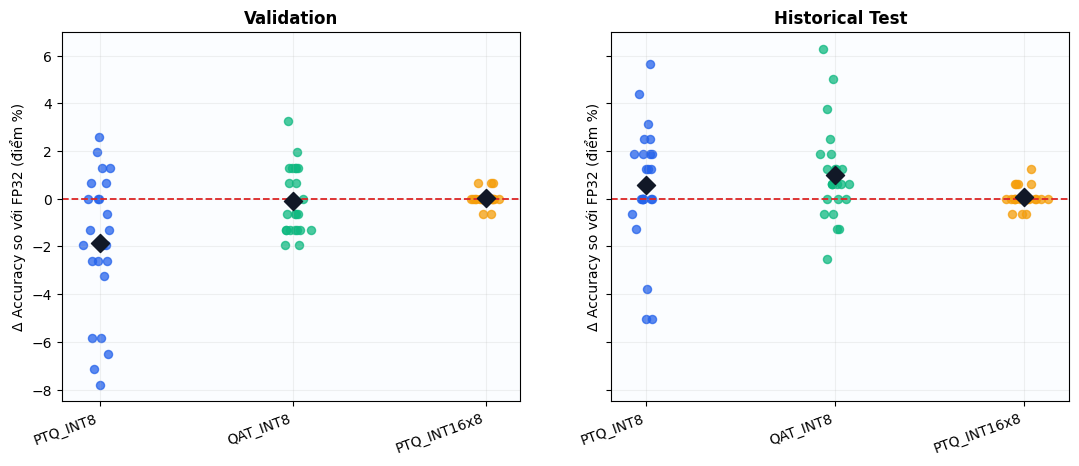

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\04_Accuracy_Delta_vs_FP32.png


In [23]:
delta_rows = []
for split, df in D_SUMMARY.items():
    fp = df[df.method_id.eq('KERAS_FP32')].set_index('trial_id')
    for method in QUANT_METHODS:
        q = df[df.method_id.eq(method)].set_index('trial_id')
        for trial_id in TRIALS:
            delta_rows.append({
                'split':split, 'trial_id':trial_id, 'variant_id':q.loc[trial_id,'variant_id'],
                'seed':int(q.loc[trial_id,'seed']), 'method_id':method,
                'delta_accuracy_pp':(q.loc[trial_id,'accuracy']-fp.loc[trial_id,'accuracy'])*100,
                'delta_macro_f1_pp':(q.loc[trial_id,'macro_f1']-fp.loc[trial_id,'macro_f1'])*100,
                'delta_asthma_recall_pp':(q.loc[trial_id,'asthma_recall']-fp.loc[trial_id,'asthma_recall'])*100,
                'delta_asthma_fn':q.loc[trial_id,'asthma_fn']-fp.loc[trial_id,'asthma_fn'],
                'changed_labels':q.loc[trial_id,'prediction_changes_vs_fp32'],
                'mae_probability':q.loc[trial_id,'mean_abs_probability_delta'],
            })
quantization_delta = pd.DataFrame(delta_rows)
display(quantization_delta.groupby(['split','method_id'])[['delta_accuracy_pp','delta_macro_f1_pp',
                                                'delta_asthma_recall_pp','delta_asthma_fn',
                                                'changed_labels','mae_probability']].agg(['mean','std','min','max']).round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
rng = np.random.default_rng(42)
for ax, split in zip(axes, ['val','test']):
    sub = quantization_delta[quantization_delta.split.eq(split)]
    for i, method in enumerate(QUANT_METHODS):
        values = sub[sub.method_id.eq(method)].delta_accuracy_pp.to_numpy()
        x = np.full(len(values), i) + rng.normal(0, .045, len(values))
        ax.scatter(x, values, s=34, alpha=.75, color=METHOD_COLORS[method])
        ax.scatter(i, values.mean(), marker='D', s=85, color='#111827', zorder=4)
    ax.axhline(0, color='#dc2626', lw=1.3, ls='--')
    ax.set_xticks(range(len(QUANT_METHODS)), QUANT_METHODS, rotation=20, ha='right')
    ax.set_title('Validation' if split=='val' else 'Historical Test', weight='bold')
    ax.set_ylabel('Δ Accuracy so với FP32 (điểm %)')
save_show(fig, '04_Accuracy_Delta_vs_FP32.png')

## D6 - Độ ổn định qua seed theo từng cấu hình

Mỗi điểm là Accuracy trung bình của ba seed; thanh lỗi là độ lệch chuẩn giữa seed 42/43/44. Đây là phép mô tả với `n=3`, không phải khoảng tin cậy tổng quát.

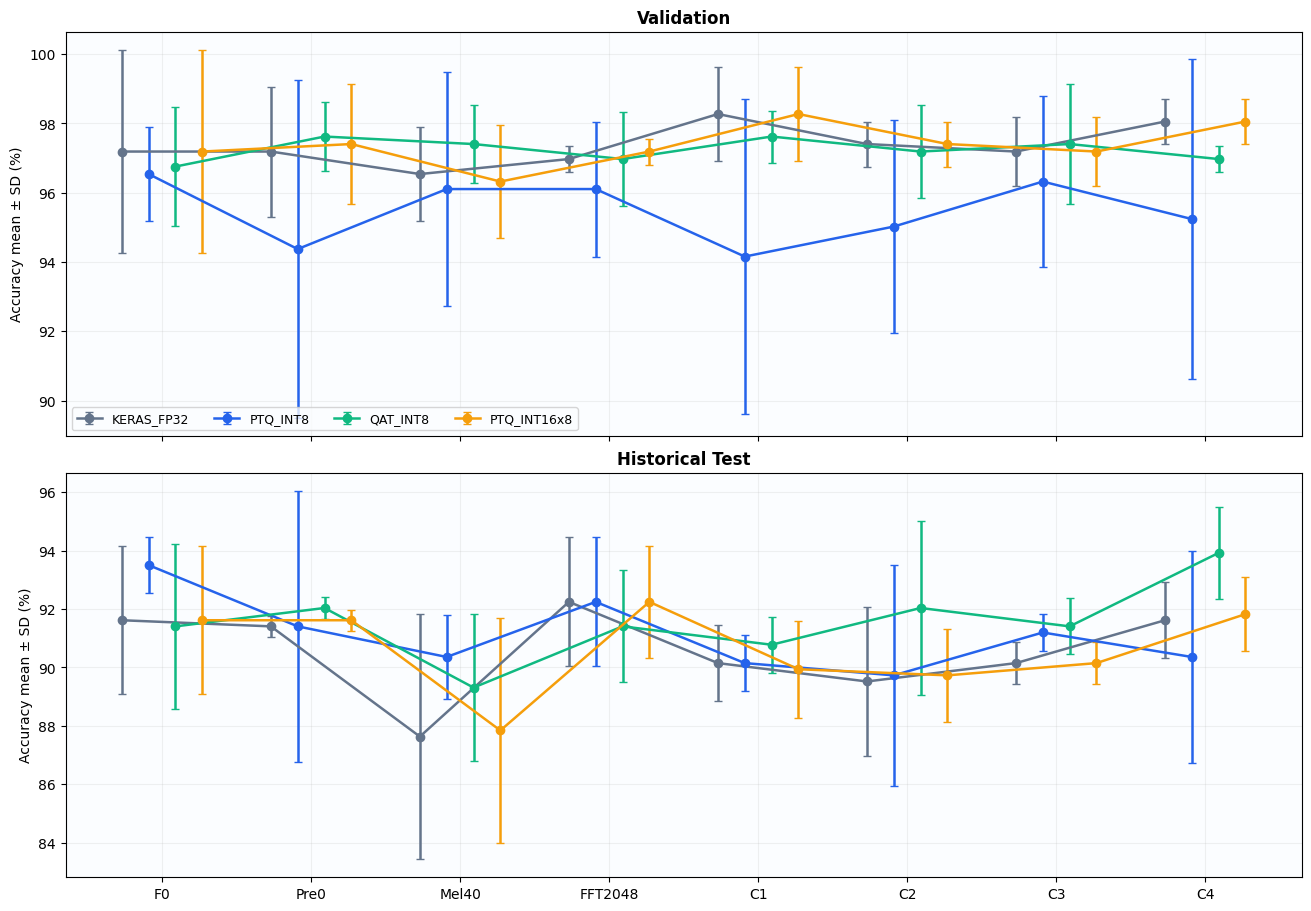

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\05_Seed_Stability_By_Variant.png


,split,variant_id,method_id,accuracy_mean,accuracy_std,macro_f1_mean,asthma_recall_mean
0,test,F0,KERAS_FP32,91.614,2.542,0.892,0.921
1,test,F0,PTQ_INT16x8,91.614,2.542,0.892,0.921
2,test,F0,PTQ_INT8,93.501,0.961,0.912,0.886
3,test,F0,QAT_INT8,91.405,2.836,0.889,0.904
4,test,combo_mel40_fft2048,KERAS_FP32,90.147,0.726,0.872,0.886
...,...,...,...,...,...,...,...
59,val,mel_40,QAT_INT8,97.403,1.125,0.966,1.000
60,val,pre_0,KERAS_FP32,97.186,1.875,0.963,0.982
61,val,pre_0,PTQ_INT16x8,97.403,1.718,0.966,0.982
62,val,pre_0,PTQ_INT8,94.372,4.874,0.919,0.842


In [24]:
seed_stats = d_all.groupby(['split','variant_id','method_id']).agg(
    accuracy_mean=('accuracy','mean'), accuracy_std=('accuracy','std'),
    macro_f1_mean=('macro_f1','mean'), asthma_recall_mean=('asthma_recall','mean')
).reset_index()
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True, constrained_layout=True)
x = np.arange(len(VARIANT_ORDER)); offsets=np.linspace(-.27,.27,len(METHODS))
for ax, split in zip(axes, ['val','test']):
    for off, method in zip(offsets, METHODS):
        s = seed_stats[(seed_stats.split==split)&(seed_stats.method_id==method)].set_index('variant_id').reindex(VARIANT_ORDER)
        ax.errorbar(x+off, s.accuracy_mean*100, yerr=s.accuracy_std*100, marker='o',
                    lw=1.8, capsize=3, label=method, color=METHOD_COLORS[method])
    ax.set_ylabel('Accuracy mean ± SD (%)')
    ax.set_title('Validation' if split=='val' else 'Historical Test', weight='bold')
axes[-1].set_xticks(x, [VARIANT_SHORT[v] for v in VARIANT_ORDER])
axes[0].legend(ncol=4, fontsize=9, loc='lower left')
save_show(fig, '05_Seed_Stability_By_Variant.png')
display(seed_stats.assign(accuracy_mean=lambda x:x.accuracy_mean*100,
                          accuracy_std=lambda x:x.accuracy_std*100).round(3))

### D6.1 - Tách từng phương pháp và từng cấu hình để khảo sát ổn định

Ba hình riêng tương ứng với ba phương pháp lượng tử. Mỗi hình có tám ô cấu hình; trong từng ô, ba điểm trên trục ngang là seed 42/43/44. Đường liền biểu diễn Validation, đường đứt biểu diễn Test; màu sắc phân biệt Accuracy, Macro-F1 và Asthma Recall. Vì vậy có thể nhận ra trực tiếp cấu hình nào ổn định giữa seed và cấu hình nào chỉ tốt ở một lần khởi tạo.

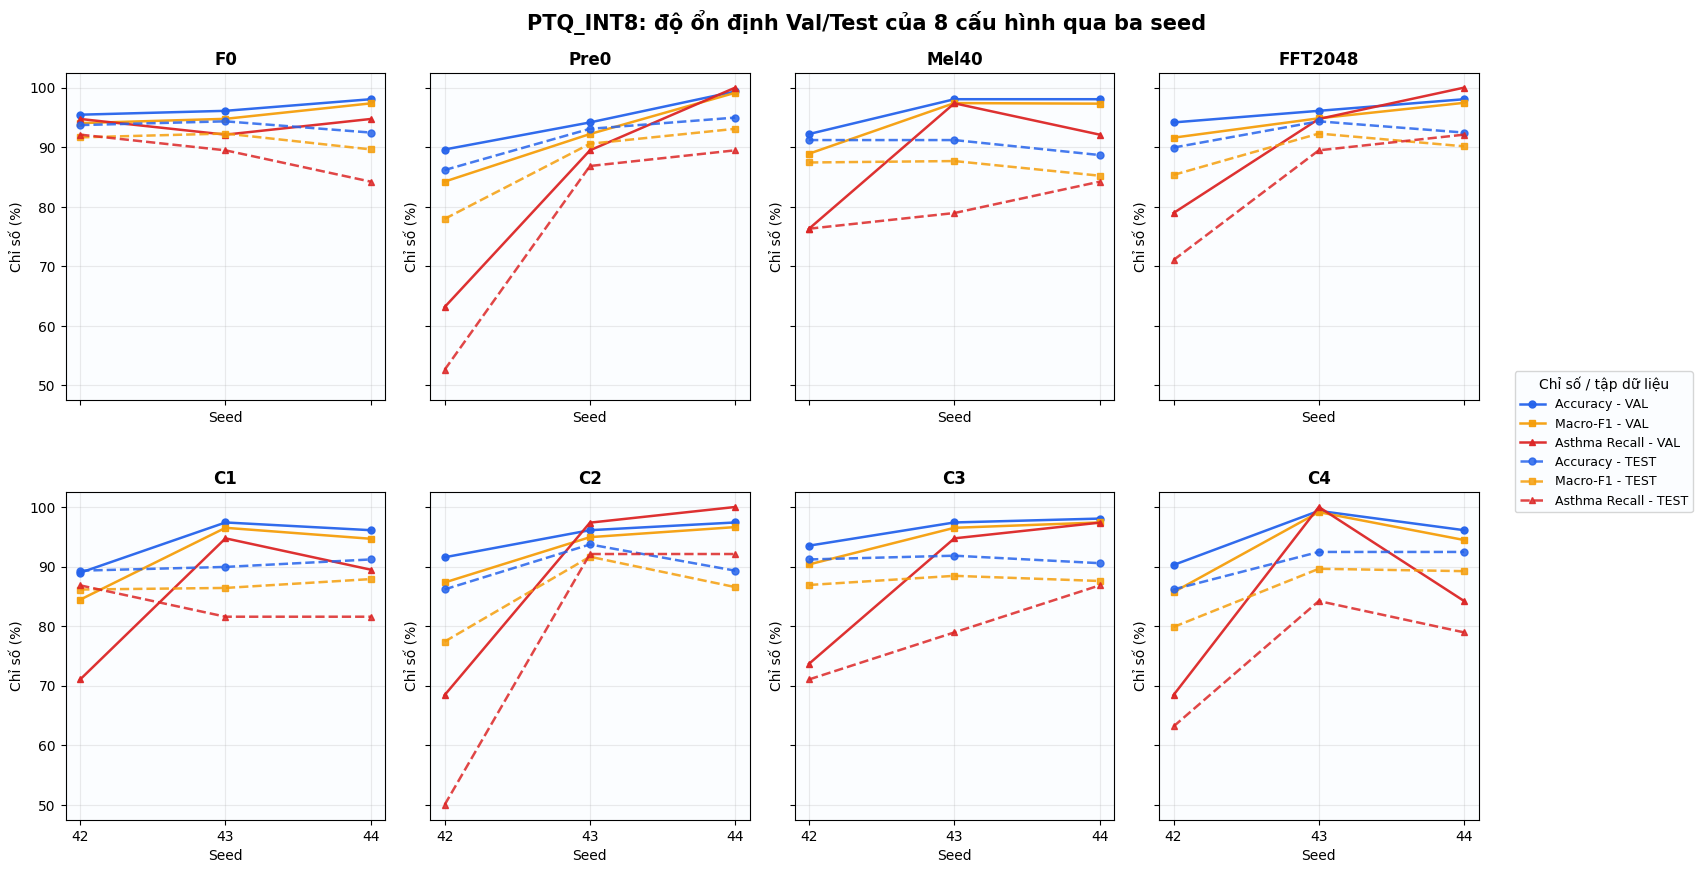

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\05_PTQ_INT8_Stability_8_Configs.png


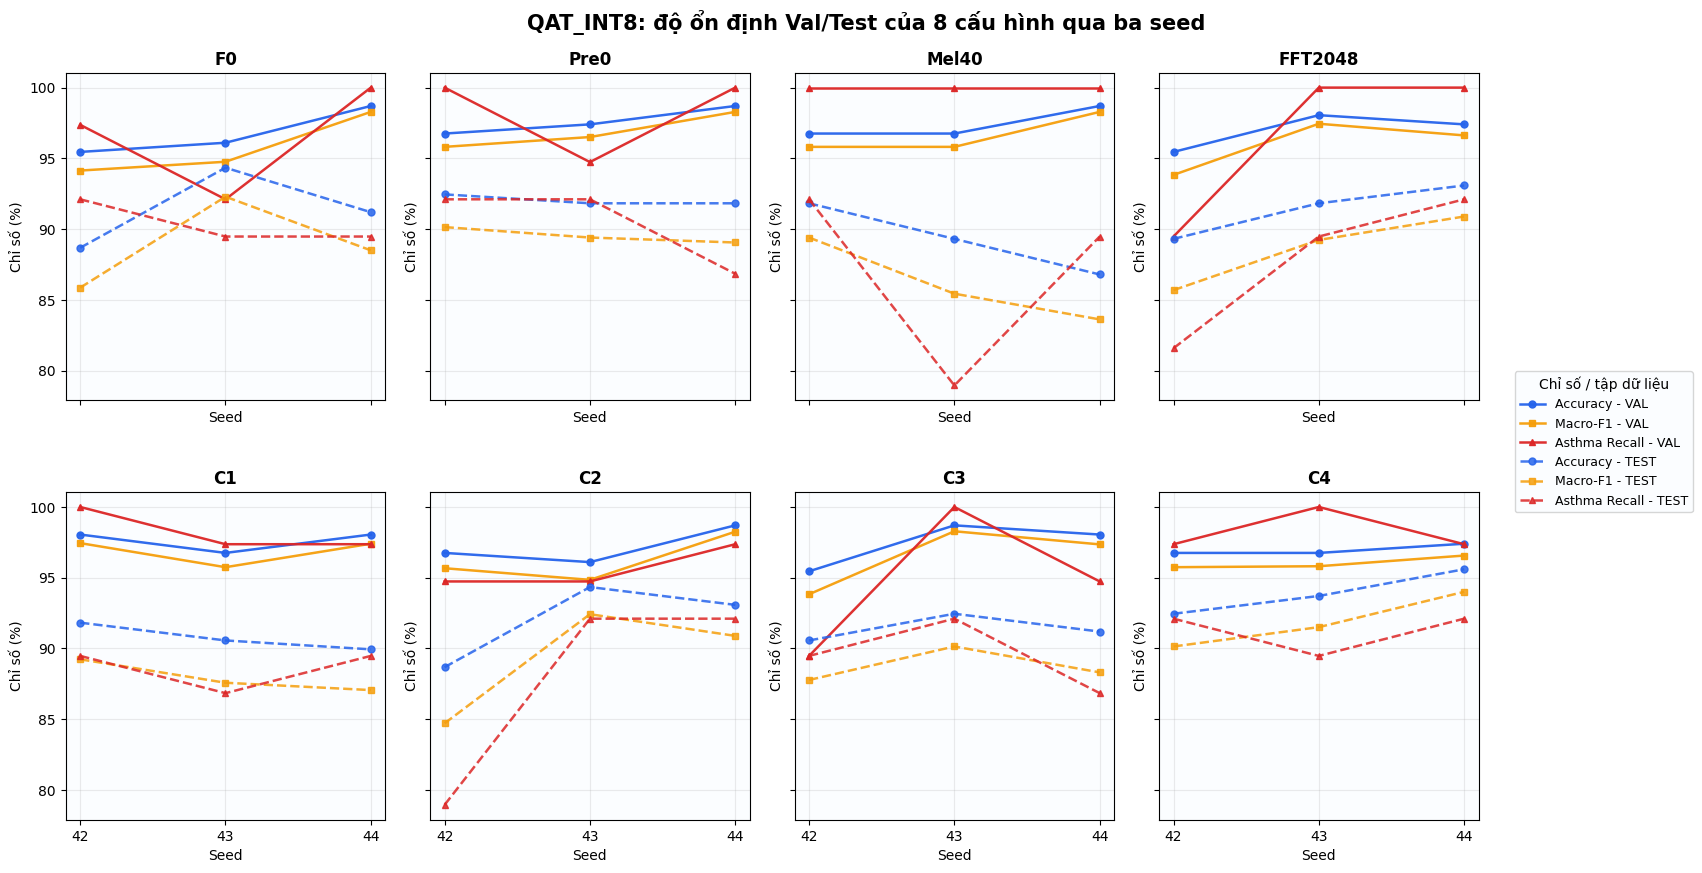

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\05_QAT_INT8_Stability_8_Configs.png


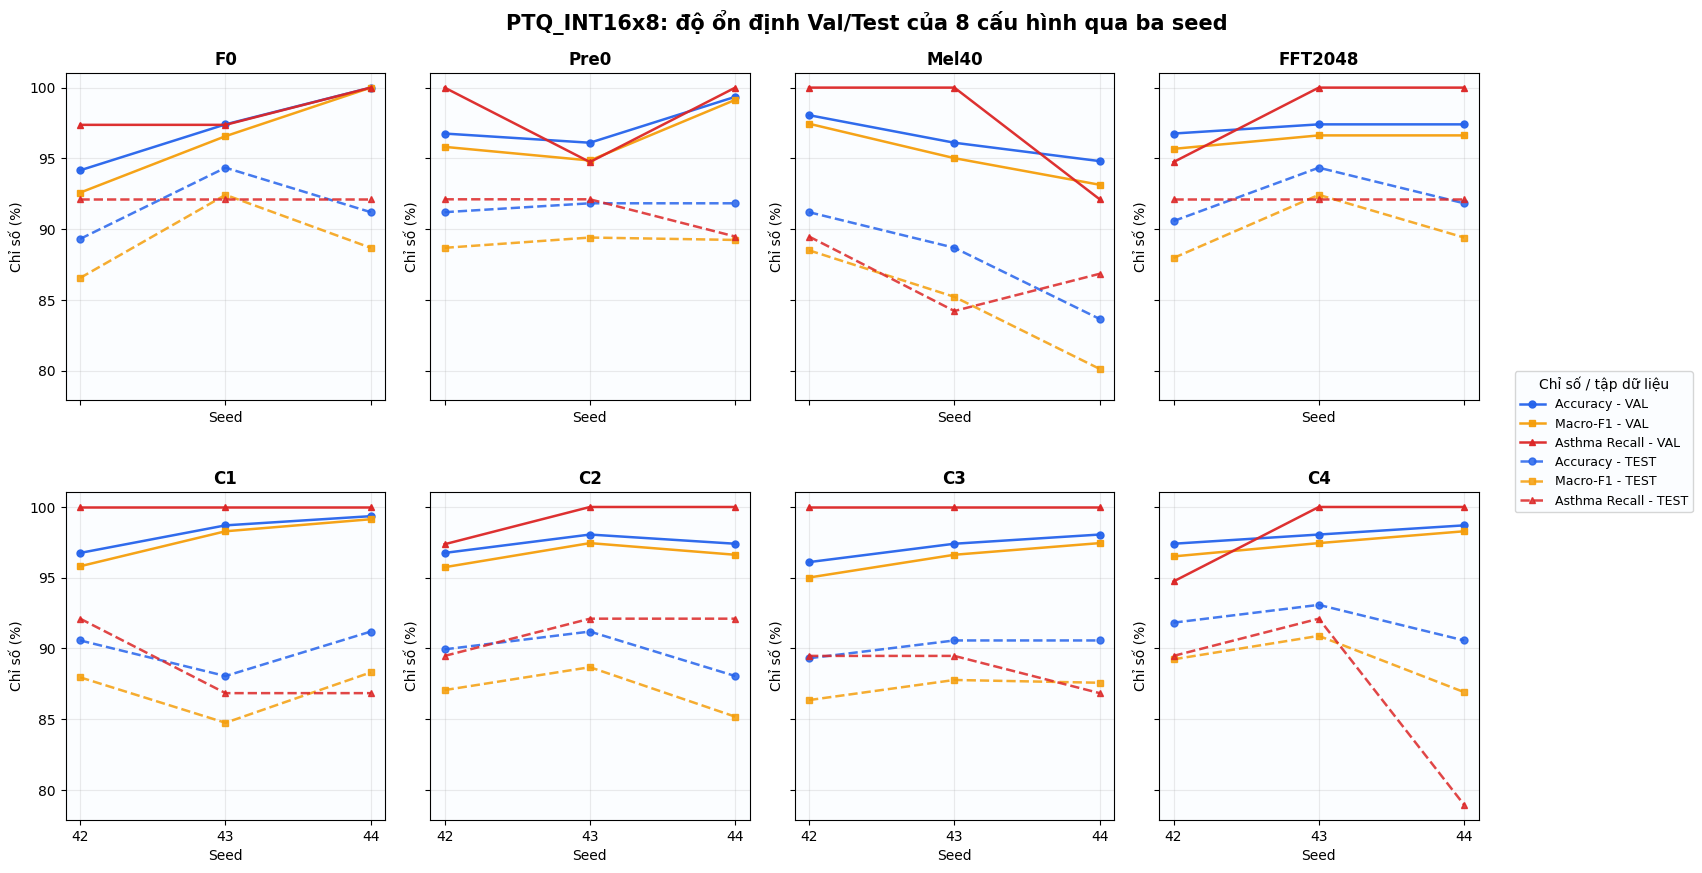

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\05_PTQ_INT16X8_Stability_8_Configs.png


#### Bảng độ ổn định chi tiết: trung bình và độ lệch chuẩn trên ba seed

,split,variant_id,method_id,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,asthma_recall_mean,asthma_recall_std,accuracy_min,accuracy_max
0,test,F0,PTQ_INT16x8,91.614,2.542,89.215,2.972,92.105,0.000,89.308,94.340
1,test,F0,PTQ_INT8,93.501,0.961,91.188,1.390,88.596,4.020,92.453,94.340
2,test,F0,QAT_INT8,91.405,2.836,88.882,3.232,90.351,1.519,88.679,94.340
3,test,combo_mel40_fft2048,PTQ_INT16x8,90.147,0.726,87.233,0.770,88.596,1.519,89.308,90.566
4,test,combo_mel40_fft2048,PTQ_INT8,91.195,0.629,87.642,0.771,78.947,7.895,90.566,91.824
5,test,combo_mel40_fft2048,QAT_INT8,91.405,0.961,88.741,1.242,89.474,2.632,90.566,92.453
6,test,combo_pre0_fft2048,PTQ_INT16x8,89.727,1.583,86.970,1.751,91.228,1.519,88.050,91.195
7,test,combo_pre0_fft2048,PTQ_INT8,89.727,3.791,85.201,7.218,78.070,24.309,86.164,93.711
8,test,combo_pre0_fft2048,QAT_INT8,92.034,2.972,89.341,4.081,87.719,7.597,88.679,94.340
9,test,combo_pre0_mel40,PTQ_INT16x8,89.937,1.664,87.004,1.963,88.596,3.039,88.050,91.195


In [25]:
STABILITY_METRICS = {
    'accuracy': ('Accuracy', '#2563eb', 'o'),
    'macro_f1': ('Macro-F1', '#f59e0b', 's'),
    'asthma_recall': ('Asthma Recall', '#dc2626', '^'),
}
stability_detail = quant_long.groupby(['split','variant_id','method_id']).agg(
    accuracy_mean=('accuracy','mean'), accuracy_std=('accuracy','std'),
    macro_f1_mean=('macro_f1','mean'), macro_f1_std=('macro_f1','std'),
    asthma_recall_mean=('asthma_recall','mean'), asthma_recall_std=('asthma_recall','std'),
    accuracy_min=('accuracy','min'), accuracy_max=('accuracy','max')
).reset_index()

for method in QUANT_METHODS:
    fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharex=True, sharey=True)
    for ax, variant in zip(axes.flat, VARIANT_ORDER):
        for split, linestyle, alpha in [('val','-',.95), ('test','--',.85)]:
            sub = D_SUMMARY[split][
                D_SUMMARY[split].method_id.eq(method) & D_SUMMARY[split].variant_id.eq(variant)
            ].sort_values('seed')
            assert sub.seed.tolist() == [42,43,44], f'{method}/{variant}/{split}: thiếu seed'
            for metric, (label, color, marker) in STABILITY_METRICS.items():
                ax.plot(sub.seed, sub[metric]*100, linestyle=linestyle, color=color, marker=marker,
                        lw=1.8, ms=5, alpha=alpha,
                        label=f'{label} - {split.upper()}')
        ax.set_title(VARIANT_SHORT[variant], weight='bold')
        ax.set_xticks([42,43,44]); ax.set_xlabel('Seed')
        ax.set_ylabel('Chỉ số (%)'); ax.grid(alpha=.25)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, title='Chỉ số / tập dữ liệu',
        ncol=1, loc='center left', bbox_to_anchor=(.86, .5),
        frameon=True, borderaxespad=0.0, fontsize=9, title_fontsize=10
    )
    fig.suptitle(
        f'{method}: độ ổn định Val/Test của 8 cấu hình qua ba seed',
        fontsize=15, weight='bold', y=.98
    )
    fig.subplots_adjust(
        left=.055, right=.84, bottom=.08, top=.91, hspace=.28, wspace=.14
    )
    safe_method = method.replace('x','X')
    save_show(fig, f'05_{safe_method}_Stability_8_Configs.png')

display(Markdown('#### Bảng độ ổn định chi tiết: trung bình và độ lệch chuẩn trên ba seed'))
display(stability_detail.assign(
    **{c: stability_detail[c]*100 for c in stability_detail.columns if c.endswith(('_mean','_std','_min','_max'))}
).round(3))

### D6.2 - Xếp hạng theo Validation: tham khảo 24 tổ hợp, thẩm định 16 tổ hợp INT8

Sử dụng `selection_score = Accuracy Val mean − SD Val` trên ba seed **chỉ để sắp xếp ứng viên**, không coi đây là kiểm định thống kê. Bảng nghiên cứu giữ đủ 24 tổ hợp gồm INT16x8; bảng triển khai chỉ có 16 tổ hợp `PTQ_INT8`/`QAT_INT8` (chưa khẳng định operator nào đã chạy trên board). Top 3 theo Validation lấy ba frontend khác nhau; Test chỉ hiển thị hậu kiểm. **Danh sách thẩm định rộng hơn** nằm cuối notebook.

#### 16 tổ hợp INT8 - xếp theo Validation (giá trị %; SD là điểm %)

,int8_val_rank,configuration,method_id,selection_score,accuracy_mean_val,accuracy_std_val,accuracy_mean_test,accuracy_std_test,asthma_recall_mean_test
0,1,C1,QAT_INT8,96.869,97.619,0.750,90.776,0.961,88.596
1,2,Pre0,QAT_INT8,96.627,97.619,0.992,92.034,0.363,90.351
2,3,C4,QAT_INT8,96.595,96.970,0.375,93.920,1.583,91.228
3,4,Mel40,QAT_INT8,96.278,97.403,1.125,89.308,2.516,86.842
4,5,C2,QAT_INT8,95.834,97.186,1.352,92.034,2.972,87.719
5,6,C3,QAT_INT8,95.685,97.403,1.718,91.405,0.961,89.474
6,7,FFT2048,QAT_INT8,95.618,96.970,1.352,91.405,1.921,87.719
7,8,F0,PTQ_INT8,95.185,96.537,1.352,93.501,0.961,88.596
8,9,F0,QAT_INT8,95.035,96.753,1.718,91.405,2.836,90.351
9,10,FFT2048,PTQ_INT8,94.156,96.104,1.948,92.243,2.209,84.211


#### Top 3 theo Val, mỗi frontend xuất hiện một lần (không phải quyết định deploy)

,selection_rank,configuration,method_id,selection_score,accuracy_mean_val,accuracy_std_val,accuracy_mean_test,accuracy_std_test,asthma_recall_mean_test
0,1,C1,QAT_INT8,96.869,97.619,0.750,90.776,0.961,88.596
1,2,Pre0,QAT_INT8,96.627,97.619,0.992,92.034,0.363,90.351
2,3,C4,QAT_INT8,96.595,96.970,0.375,93.920,1.583,91.228


#### 3 tổ hợp dẫn đầu toàn bộ 24 nhánh - CHỈ THAM KHẢO, gồm INT16x8

,research_rank,configuration,method_id,selection_score,accuracy_mean_val,accuracy_std_val,accuracy_mean_test,accuracy_std_test,asthma_recall_mean_test
0,1,C4,PTQ_INT16x8,97.403,98.052,0.649,91.824,1.258,86.842
1,2,C1,PTQ_INT16x8,96.917,98.268,1.352,89.937,1.664,88.596
2,3,C1,QAT_INT8,96.869,97.619,0.750,90.776,0.961,88.596


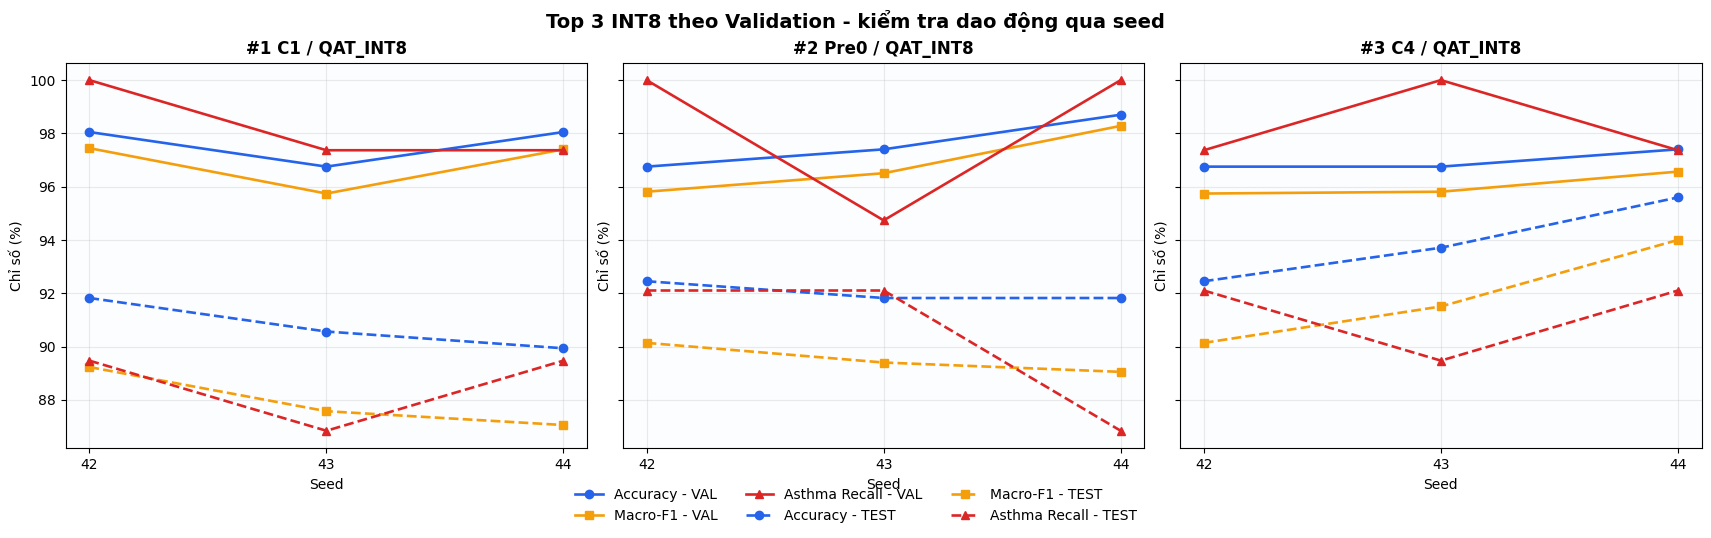

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\05_Top3_INT8_Validation_Handoff_Stability.png


In [26]:
val_rank = stability_detail[
    stability_detail.split.eq('val') & stability_detail.method_id.isin(QUANT_METHODS)
].drop(columns='split').set_index(['variant_id','method_id'])
test_rank = stability_detail[
    stability_detail.split.eq('test') & stability_detail.method_id.isin(QUANT_METHODS)
].drop(columns='split').set_index(['variant_id','method_id'])
research_ranking = val_rank.join(test_rank, lsuffix='_val', rsuffix='_test').reset_index()
research_ranking['configuration'] = research_ranking.variant_id.map(VARIANT_SHORT)
research_ranking['selection_score'] = research_ranking.accuracy_mean_val - research_ranking.accuracy_std_val
research_ranking = research_ranking.sort_values(
    ['selection_score','accuracy_mean_val','asthma_recall_mean_val','accuracy_std_val'],
    ascending=[False,False,False,True]
).reset_index(drop=True)
research_ranking.insert(0, 'research_rank', np.arange(1, len(research_ranking)+1))

DEPLOY_METHODS = ['PTQ_INT8','QAT_INT8']
handoff_ranking = research_ranking[research_ranking.method_id.isin(DEPLOY_METHODS)].copy()
handoff_ranking = handoff_ranking.drop(columns='research_rank').reset_index(drop=True)
handoff_ranking.insert(0, 'int8_val_rank', np.arange(1, len(handoff_ranking)+1))
top3_handoff = handoff_ranking.drop_duplicates('variant_id', keep='first').head(3).copy()
top3_handoff.insert(0, 'selection_rank', [1,2,3])
assert len(research_ranking)==24 and len(handoff_ranking)==16
assert len(top3_handoff)==3 and top3_handoff.variant_id.nunique()==3

def view_percent(df, columns):
    v = df[columns].copy()
    for c in v.columns:
        if c in ('selection_score','accuracy_mean_val','accuracy_std_val',
                 'accuracy_mean_test','accuracy_std_test','asthma_recall_mean_test'):
            v[c] = (v[c]*100).round(3)
    return v

cols = ['int8_val_rank','configuration','method_id','selection_score',
        'accuracy_mean_val','accuracy_std_val','accuracy_mean_test',
        'accuracy_std_test','asthma_recall_mean_test']
display(Markdown('#### 16 tổ hợp INT8 - xếp theo Validation (giá trị %; SD là điểm %)'))
display(view_percent(handoff_ranking, cols))
display(Markdown('#### Top 3 theo Val, mỗi frontend xuất hiện một lần (không phải quyết định deploy)'))
display(view_percent(top3_handoff, ['selection_rank'] + cols[1:]))
display(Markdown('#### 3 tổ hợp dẫn đầu toàn bộ 24 nhánh - CHỈ THAM KHẢO, gồm INT16x8'))
display(view_percent(research_ranking.head(3),
                     ['research_rank','configuration','method_id','selection_score',
                      'accuracy_mean_val','accuracy_std_val','accuracy_mean_test',
                      'accuracy_std_test','asthma_recall_mean_test']))

fig, axes = plt.subplots(1,3,figsize=(17,4.9),sharey=True,constrained_layout=True)
metric_style = {'accuracy':('#2563eb','o','Accuracy'),
                'macro_f1':('#f59e0b','s','Macro-F1'),
                'asthma_recall':('#dc2626','^','Asthma Recall')}
for ax, row in zip(axes, top3_handoff.itertuples()):
    for split, linestyle in [('val','-'),('test','--')]:
        part = D_SUMMARY[split][
            D_SUMMARY[split].variant_id.eq(row.variant_id) & D_SUMMARY[split].method_id.eq(row.method_id)
        ].sort_values('seed')
        for metric, (color,marker,label) in metric_style.items():
            ax.plot(part.seed,part[metric]*100,linestyle=linestyle,marker=marker,
                    color=color,lw=1.9,ms=6,label=f'{label} - {split.upper()}')
    ax.set_title(f'#{row.selection_rank} {row.configuration} / {row.method_id}',weight='bold')
    ax.set_xticks([42,43,44]); ax.set_xlabel('Seed'); ax.set_ylabel('Chỉ số (%)'); ax.grid(alpha=.25)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles,labels,ncol=3,loc='lower center',bbox_to_anchor=(.5,-.08),frameon=False)
fig.suptitle('Top 3 INT8 theo Validation - kiểm tra dao động qua seed',fontsize=14,weight='bold')
save_show(fig, '05_Top3_INT8_Validation_Handoff_Stability.png')

### D6.3 - Xếp hạng theo Test: hậu kiểm 24 tổ hợp, thẩm định 16 tổ hợp INT8

Sử dụng `test_score = Accuracy Test mean − SD Test` trên ba seed để mô tả độ ổn định hậu kiểm. Bảng nghiên cứu giữ đủ 24 tổ hợp gồm INT16x8; bảng triển khai giữ 16 tổ hợp `PTQ_INT8`/`QAT_INT8`. **Thứ hạng Test không được dùng để quay lại chọn mô hình hoặc điều chỉnh pipeline**; quyết định nghiên cứu vẫn dựa trên Validation ở D6.2.

#### 16 tổ hợp INT8 - xếp theo Test (hậu kiểm; giá trị %; SD là điểm %)

,int8_test_rank,configuration,method_id,test_score,accuracy_mean_test,accuracy_std_test,accuracy_mean_val,accuracy_std_val,asthma_recall_mean_test
0,1,F0,PTQ_INT8,92.540,93.501,0.961,96.537,1.352,88.596
1,2,C4,QAT_INT8,92.338,93.920,1.583,96.970,0.375,91.228
2,3,Pre0,QAT_INT8,91.670,92.034,0.363,97.619,0.992,90.351
3,4,C3,PTQ_INT8,90.566,91.195,0.629,96.320,2.458,78.947
4,5,C3,QAT_INT8,90.444,91.405,0.961,97.403,1.718,89.474
5,6,FFT2048,PTQ_INT8,90.034,92.243,2.209,96.104,1.948,84.211
6,7,C1,QAT_INT8,89.815,90.776,0.961,97.619,0.750,88.596
7,8,FFT2048,QAT_INT8,89.483,91.405,1.921,96.970,1.352,87.719
8,9,C1,PTQ_INT8,89.186,90.147,0.961,94.156,4.545,83.333
9,10,C2,QAT_INT8,89.061,92.034,2.972,97.186,1.352,87.719


#### Top 3 theo Test, mỗi frontend xuất hiện một lần (chỉ mô tả hậu kiểm)

,test_selection_rank,configuration,method_id,test_score,accuracy_mean_test,accuracy_std_test,accuracy_mean_val,accuracy_std_val,asthma_recall_mean_test
0,1,F0,PTQ_INT8,92.540,93.501,0.961,96.537,1.352,88.596
1,2,C4,QAT_INT8,92.338,93.920,1.583,96.970,0.375,91.228
2,3,Pre0,QAT_INT8,91.670,92.034,0.363,97.619,0.992,90.351


#### 3 tổ hợp dẫn đầu toàn bộ 24 nhánh theo Test - CHỈ THAM KHẢO, gồm INT16x8

,test_research_rank,configuration,method_id,test_score,accuracy_mean_test,accuracy_std_test,accuracy_mean_val,accuracy_std_val,asthma_recall_mean_test
0,1,F0,PTQ_INT8,92.540,93.501,0.961,96.537,1.352,88.596
1,2,C4,QAT_INT8,92.338,93.920,1.583,96.970,0.375,91.228
2,3,Pre0,QAT_INT8,91.670,92.034,0.363,97.619,0.992,90.351


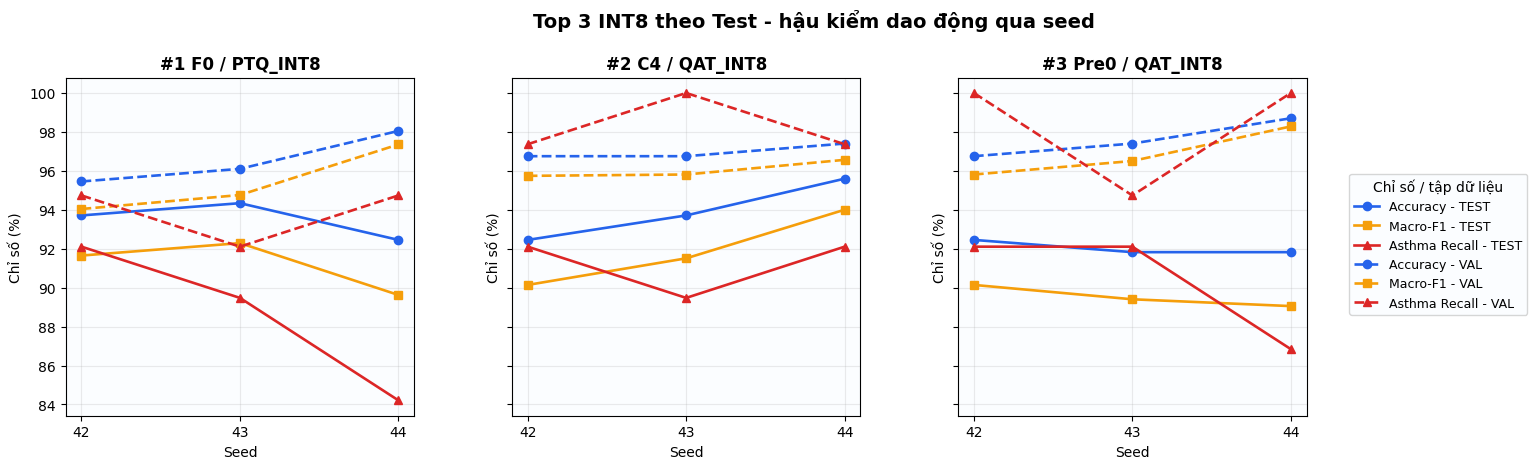

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\05_Top3_INT8_Test_Handoff_Stability.png


In [27]:
# D6.3 - Xếp hạng mô tả theo Test; không dùng để tái chọn mô hình.
test_research_ranking = research_ranking.drop(
    columns=['research_rank', 'selection_score']
).copy()
test_research_ranking['test_score'] = (
    test_research_ranking.accuracy_mean_test
    - test_research_ranking.accuracy_std_test
)
test_research_ranking = test_research_ranking.sort_values(
    ['test_score', 'accuracy_mean_test', 'asthma_recall_mean_test', 'accuracy_std_test'],
    ascending=[False, False, False, True],
).reset_index(drop=True)
test_research_ranking.insert(
    0, 'test_research_rank', np.arange(1, len(test_research_ranking) + 1)
)

test_handoff_ranking = test_research_ranking[
    test_research_ranking.method_id.isin(DEPLOY_METHODS)
].copy()
test_handoff_ranking = test_handoff_ranking.drop(
    columns='test_research_rank'
).reset_index(drop=True)
test_handoff_ranking.insert(
    0, 'int8_test_rank', np.arange(1, len(test_handoff_ranking) + 1)
)
top3_test_handoff = test_handoff_ranking.drop_duplicates(
    'variant_id', keep='first'
).head(3).copy()
top3_test_handoff.insert(0, 'test_selection_rank', [1, 2, 3])

assert len(test_research_ranking) == 24
assert len(test_handoff_ranking) == 16
assert len(top3_test_handoff) == 3
assert top3_test_handoff.variant_id.nunique() == 3

def view_test_percent(df, columns):
    view = df[columns].copy()
    percent_columns = {
        'test_score',
        'accuracy_mean_test', 'accuracy_std_test',
        'accuracy_mean_val', 'accuracy_std_val',
        'asthma_recall_mean_test',
    }
    for column in view.columns:
        if column in percent_columns:
            view[column] = (view[column] * 100).round(3)
    return view

test_cols = [
    'int8_test_rank', 'configuration', 'method_id', 'test_score',
    'accuracy_mean_test', 'accuracy_std_test',
    'accuracy_mean_val', 'accuracy_std_val',
    'asthma_recall_mean_test',
]
display(Markdown(
    '#### 16 tổ hợp INT8 - xếp theo Test '
    '(hậu kiểm; giá trị %; SD là điểm %)'
))
display(view_test_percent(test_handoff_ranking, test_cols))

display(Markdown(
    '#### Top 3 theo Test, mỗi frontend xuất hiện một lần '
    '(chỉ mô tả hậu kiểm)'
))
display(view_test_percent(
    top3_test_handoff,
    ['test_selection_rank'] + test_cols[1:],
))

display(Markdown(
    '#### 3 tổ hợp dẫn đầu toàn bộ 24 nhánh theo Test '
    '- CHỈ THAM KHẢO, gồm INT16x8'
))
display(view_test_percent(
    test_research_ranking.head(3),
    [
        'test_research_rank', 'configuration', 'method_id', 'test_score',
        'accuracy_mean_test', 'accuracy_std_test',
        'accuracy_mean_val', 'accuracy_std_val',
        'asthma_recall_mean_test',
    ],
))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.9), sharey=True)
for ax, row in zip(axes, top3_test_handoff.itertuples()):
    for split, linestyle in [('test', '-'), ('val', '--')]:
        part = D_SUMMARY[split][
            D_SUMMARY[split].variant_id.eq(row.variant_id)
            & D_SUMMARY[split].method_id.eq(row.method_id)
        ].sort_values('seed')
        for metric, (color, marker, label) in metric_style.items():
            ax.plot(
                part.seed,
                part[metric] * 100,
                linestyle=linestyle,
                marker=marker,
                color=color,
                lw=1.9,
                ms=6,
                label=f'{label} - {split.upper()}',
            )
    ax.set_title(
        f'#{row.test_selection_rank} {row.configuration} / {row.method_id}',
        weight='bold',
    )
    ax.set_xticks([42, 43, 44])
    ax.set_xlabel('Seed')
    ax.set_ylabel('Chỉ số (%)')
    ax.grid(alpha=.25)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title='Chỉ số / tập dữ liệu',
    ncol=1,
    loc='center left',
    bbox_to_anchor=(.815, .5),
    frameon=True,
    borderaxespad=0.0,
    fontsize=9,
    title_fontsize=10,
)
fig.suptitle(
    'Top 3 INT8 theo Test - hậu kiểm dao động qua seed',
    fontsize=14,
    weight='bold',
    y=.98,
)
fig.subplots_adjust(left=.06, right=.79, bottom=.15, top=.84, wspace=.28)
save_show(fig, '05_Top3_INT8_Test_Handoff_Stability.png')

## D7 - Asthma FN và Non-Asthma FP trên historical Test

Accuracy không đủ để quyết định deployment. Hai heatmap sau cho thấy số Asthma bị bỏ sót (`FN`) và số Non-Asthma bị báo nhầm (`FP`) của từng checkpoint/method.

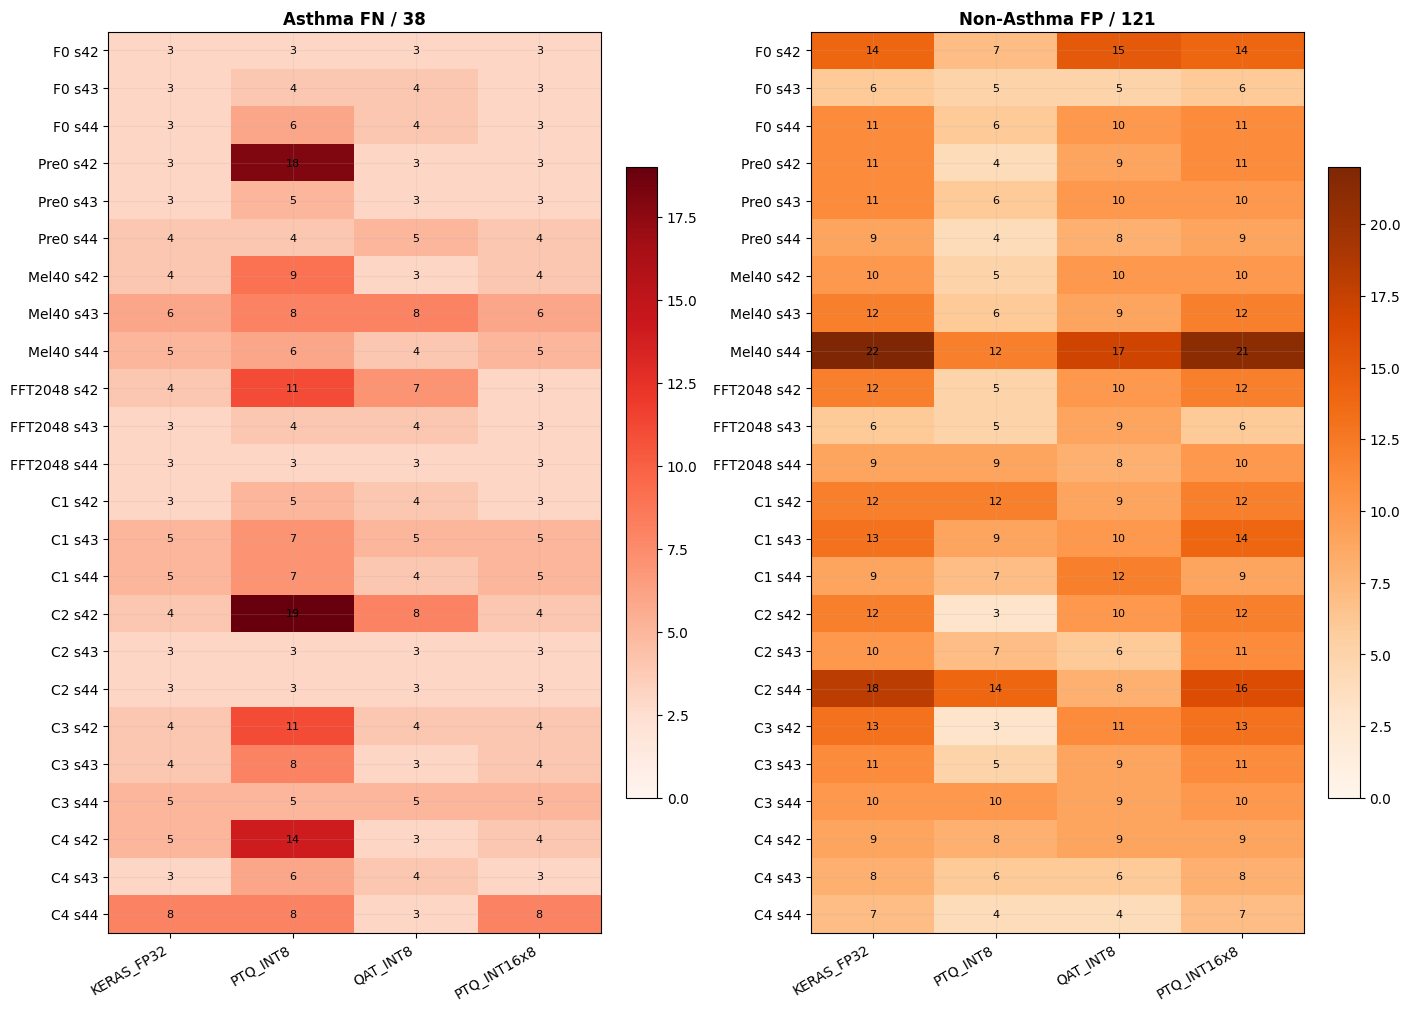

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\06_Test_FN_FP_Heatmaps.png


In [28]:
test = D_SUMMARY['test']
fig, axes = plt.subplots(1, 2, figsize=(14, 10), constrained_layout=True)
for ax, metric, title, cmap in [
    (axes[0], 'asthma_fn', 'Asthma FN / 38', 'Reds'),
    (axes[1], 'non_asthma_fp', 'Non-Asthma FP / 121', 'Oranges')]:
    mat = test.pivot(index='trial_id', columns='method_id', values=metric).reindex(index=trial_order, columns=METHODS)
    im=ax.imshow(mat.to_numpy(), aspect='auto', cmap=cmap, vmin=0)
    ax.set_xticks(range(len(METHODS)), METHODS, rotation=30, ha='right')
    ax.set_yticks(range(len(trial_labels)), trial_labels)
    ax.set_title(title, weight='bold')
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]): ax.text(j,i,str(int(mat.iloc[i,j])),ha='center',va='center',fontsize=8)
    fig.colorbar(im, ax=ax, shrink=.7)
save_show(fig, '06_Test_FN_FP_Heatmaps.png')

## D8 - Paired label flips: lỗi được sửa và lỗi mới phát sinh

So sánh theo đúng từng WAV giữa FP32 và model lượng tử. `FIXED` là FP32 sai nhưng quantized đúng; `NEW_ERROR` là FP32 đúng nhưng quantized sai. Các thay đổi đúng → đúng hoặc sai → sai không được tính là flip.

changed           fixed          new_error         
                     mean  sum max   mean  sum max      mean  sum max
split method_id                                                      
test  PTQ_INT16x8   0.375    9   2  0.250    6   2     0.125    3   1
      PTQ_INT8     10.250  246  24  5.583  134  10     4.667  112  16
      QAT_INT8      6.833  164  12  4.208  101  11     2.625   63   7
val   PTQ_INT16x8   0.208    5   1  0.125    3   1     0.083    2   1
      PTQ_INT8      7.208  173  20  2.167   52   6     5.042  121  15
      QAT_INT8      4.167  100   9  2.000   48   5     2.167   52   5

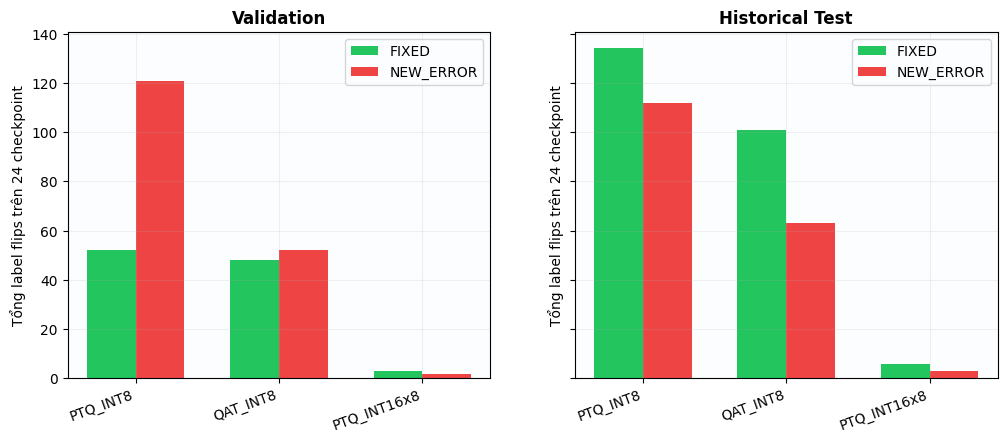

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\07_Paired_Label_Flips.png


In [29]:
flip_rows=[]
for split, df in PRED.items():
    for trial_id in TRIALS:
        block=df[df.trial_id.eq(trial_id)]
        fp=block[block.method_id.eq('KERAS_FP32')].set_index('file')
        for method in QUANT_METHODS:
            q=block[block.method_id.eq(method)].set_index('file').loc[fp.index]
            changed=fp.predicted_label.ne(q.predicted_label)
            fixed=changed & fp.predicted_label.ne(fp.true_label) & q.predicted_label.eq(fp.true_label)
            new_error=changed & fp.predicted_label.eq(fp.true_label) & q.predicted_label.ne(fp.true_label)
            flip_rows.append({'split':split,'trial_id':trial_id,'variant_id':block.variant_id.iloc[0] if 'variant_id' in block else trial_id.split('__')[0],
                              'method_id':method,'changed':int(changed.sum()),
                              'fixed':int(fixed.sum()),'new_error':int(new_error.sum())})
flips=pd.DataFrame(flip_rows)
flip_summary=flips.groupby(['split','method_id'])[['changed','fixed','new_error']].agg(['mean','sum','max']).round(3)
display(flip_summary)
fig, axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
for ax,split in zip(axes,['val','test']):
    s=flips[flips.split.eq(split)].groupby('method_id')[['fixed','new_error']].sum().reindex(QUANT_METHODS)
    x=np.arange(len(s)); w=.34
    ax.bar(x-w/2,s.fixed,w,label='FIXED',color='#22c55e')
    ax.bar(x+w/2,s.new_error,w,label='NEW_ERROR',color='#ef4444')
    ax.set_xticks(x,s.index,rotation=20,ha='right'); ax.set_ylabel('Tổng label flips trên 24 checkpoint')
    ax.set_title('Validation' if split=='val' else 'Historical Test',weight='bold'); ax.legend()
save_show(fig,'07_Paired_Label_Flips.png')

## D9 - Trade-off kích thước model và hiệu năng Test

Biểu đồ dùng toàn bộ 96 phiên bản Test. Kích thước nhỏ không tự động đồng nghĩa tốt hơn; ứng viên triển khai phải xét đồng thời Accuracy, Asthma Recall/FN, kiểu I/O và benchmark ESP32-S3.

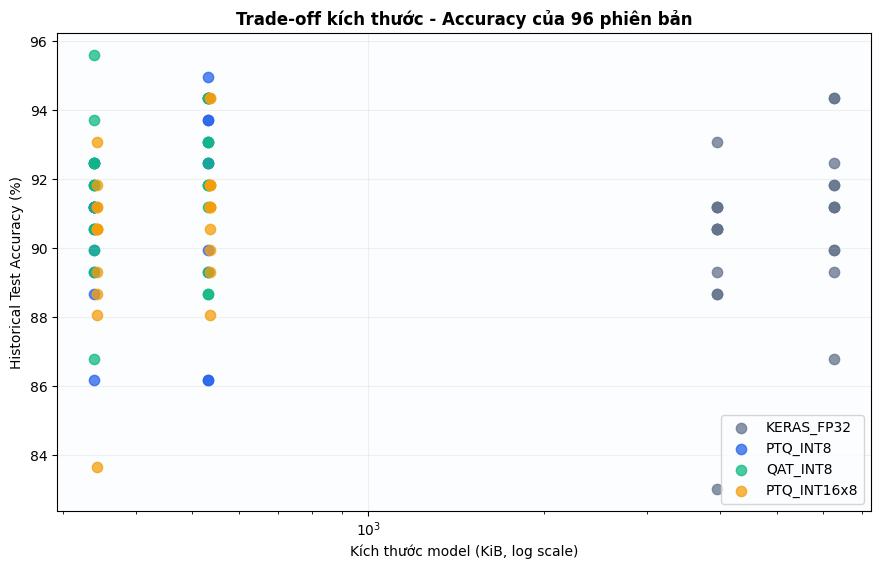

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\08_Model_Size_vs_Test_Accuracy.png


,mean_KiB,min_KiB,max_KiB,compression_vs_fp32
method_id,,,,
KERAS_FP32,5100.60,3948.60,6252.60,1.00
PTQ_INT8,435.23,339.23,531.23,11.72
QAT_INT8,435.81,339.80,531.81,11.70
PTQ_INT16x8,438.91,342.91,534.91,11.62


In [30]:
fig, ax=plt.subplots(figsize=(10.5,6.2))
for method in METHODS:
    s=test[test.method_id.eq(method)]
    ax.scatter(s.model_size_bytes/1024,s.accuracy*100,s=55,alpha=.75,label=method,color=METHOD_COLORS[method])
ax.set_xscale('log'); ax.set_xlabel('Kích thước model (KiB, log scale)'); ax.set_ylabel('Historical Test Accuracy (%)')
ax.set_title('Trade-off kích thước - Accuracy của 96 phiên bản',weight='bold'); ax.legend()
save_show(fig,'08_Model_Size_vs_Test_Accuracy.png')
sizes=test.groupby('method_id').model_size_bytes.agg(['mean','min','max']).reindex(METHODS)
fp_mean=sizes.loc['KERAS_FP32','mean']; sizes['compression_vs_fp32']=fp_mean/sizes['mean']
display((sizes.assign(mean_KiB=sizes['mean']/1024,min_KiB=sizes['min']/1024,max_KiB=sizes['max']/1024)
         [['mean_KiB','min_KiB','max_KiB','compression_vs_fp32']]).round(2))

## D10 - Validation rank so với Test rank

Mỗi heatmap biểu diễn 24 checkpoint của một phương pháp: **8 cấu hình × 3 seed**. Mỗi ô ghi `hạng Validation → hạng Test` và độ đổi hạng `(Test − Validation)`. **Xanh lam** là tăng hạng trên Test, **trắng** là gần như giữ hạng, **đỏ** là tụt hạng. Không dùng Test rank để quay lại điều chỉnh frontend; đây chỉ là phần mô tả hậu kiểm.

#### 20 checkpoint có thay đổi thứ hạng lớn nhất

,trial_id,method_id,rank_val,rank_test,rank_change_val_to_test,generalization_gap_pp
83,mel_40__V1__s44,QAT_INT8,1.0,24.0,23.0,-11.909
41,combo_pre0_mel40__V1__s43,PTQ_INT16x8,4.0,22.0,18.0,-10.651
82,mel_40__V1__s44,PTQ_INT8,3.0,21.0,18.0,-9.373
7,F0__V1__s43,QAT_INT8,20.0,2.0,-18.0,-1.764
31,combo_pre0_fft2048__V1__s43,QAT_INT8,20.0,2.0,-18.0,-1.764
40,combo_pre0_mel40__V1__s43,KERAS_FP32,4.0,21.0,17.0,-10.022
89,pre_0__V1__s43,PTQ_INT16x8,20.0,4.0,-16.0,-4.280
11,F0__V1__s44,QAT_INT8,1.0,15.0,14.0,-7.506
64,fft_2048__V1__s43,KERAS_FP32,15.0,1.0,-14.0,-2.414
22,combo_mel40_fft2048__V1__s44,PTQ_INT8,3.0,16.0,13.0,-7.486


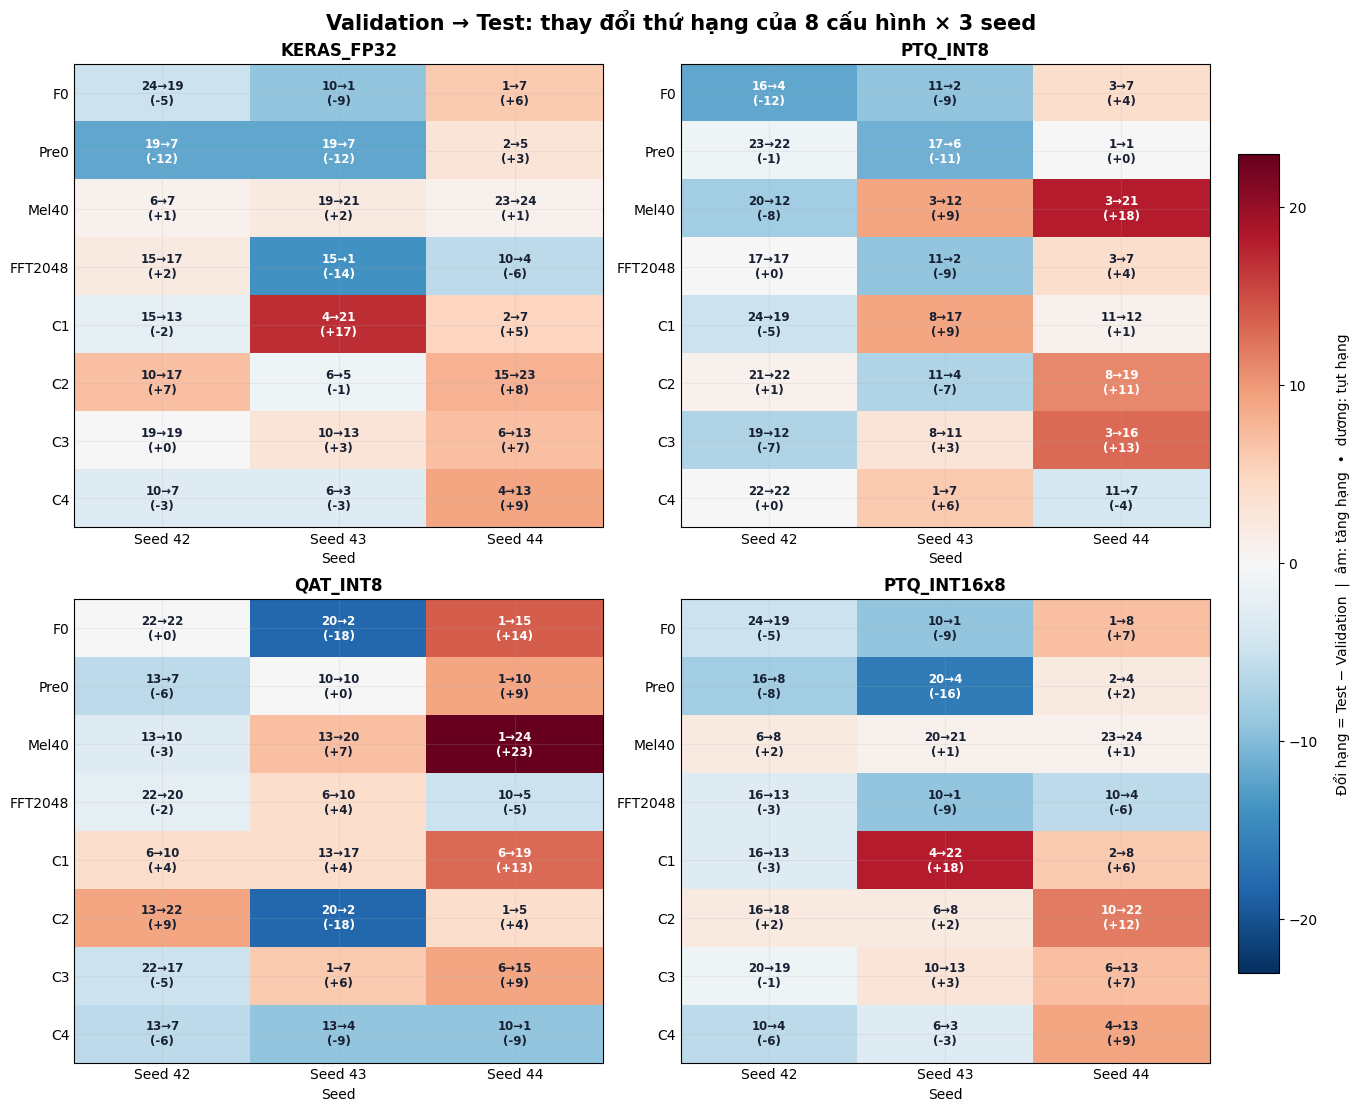

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\09_Validation_vs_Test_Rank.png


In [31]:
rank_base = d_all[['split', 'trial_id', 'variant_id', 'seed', 'method_id', 'accuracy']].copy()
rank_base['rank'] = (
    rank_base.groupby(['split', 'method_id']).accuracy
    .rank(method='min', ascending=False).astype(int)
)
r = rank_base.pivot(
    index=['trial_id', 'variant_id', 'seed', 'method_id'],
    columns='split',
    values=['accuracy', 'rank'],
).reset_index()
r.columns = [
    'trial_id', 'variant_id', 'seed', 'method_id',
    'accuracy_test', 'accuracy_val', 'rank_test', 'rank_val',
]
r['generalization_gap_pp'] = (r.accuracy_test - r.accuracy_val) * 100
r['rank_change_val_to_test'] = r.rank_test - r.rank_val

rank_table = r.copy()
rank_table['abs_rank_change'] = rank_table.rank_change_val_to_test.abs()
rank_table = rank_table.sort_values(
    ['abs_rank_change', 'rank_change_val_to_test'],
    ascending=[False, False],
)
display(Markdown('#### 20 checkpoint có thay đổi thứ hạng lớn nhất'))
display(rank_table[[
    'trial_id', 'method_id', 'rank_val', 'rank_test',
    'rank_change_val_to_test', 'generalization_gap_pp',
]].head(20).round(3))

rank_limit = int(np.abs(r['rank_change_val_to_test']).max())
fig, axes = plt.subplots(2, 2, figsize=(13.5, 11), constrained_layout=True)

for ax, method in zip(axes.flat, METHODS):
    sub = r[r.method_id.eq(method)].copy()
    change = (
        sub.pivot(index='variant_id', columns='seed', values='rank_change_val_to_test')
        .reindex(index=VARIANT_ORDER, columns=[42, 43, 44])
    )
    val_rank = (
        sub.pivot(index='variant_id', columns='seed', values='rank_val')
        .reindex(index=VARIANT_ORDER, columns=[42, 43, 44])
    )
    test_rank = (
        sub.pivot(index='variant_id', columns='seed', values='rank_test')
        .reindex(index=VARIANT_ORDER, columns=[42, 43, 44])
    )

    image = ax.imshow(
        change.to_numpy(dtype=float),
        cmap='RdBu_r',
        vmin=-rank_limit,
        vmax=rank_limit,
        aspect='auto',
    )
    for row_idx in range(len(VARIANT_ORDER)):
        for col_idx in range(3):
            rv = int(val_rank.iloc[row_idx, col_idx])
            rt = int(test_rank.iloc[row_idx, col_idx])
            rank_delta = int(change.iloc[row_idx, col_idx])
            text_color = 'white' if abs(rank_delta) >= max(5, rank_limit * .45) else '#172033'
            ax.text(
                col_idx, row_idx, f'{rv}→{rt}\n({rank_delta:+d})',
                ha='center', va='center', fontsize=8.5,
                color=text_color, weight='semibold',
            )

    ax.set_xticks(range(3), ['Seed 42', 'Seed 43', 'Seed 44'])
    ax.set_yticks(
        range(len(VARIANT_ORDER)),
        [VARIANT_SHORT[variant] for variant in VARIANT_ORDER],
    )
    ax.set_title(method, weight='bold', fontsize=12)
    ax.set_xlabel('Seed')
    ax.tick_params(axis='both', length=0)

colorbar = fig.colorbar(image, ax=axes.ravel().tolist(), shrink=.82, pad=.025)
colorbar.set_label(
    'Đổi hạng = Test − Validation  |  âm: tăng hạng  •  dương: tụt hạng',
    rotation=90, labelpad=12,
)
fig.suptitle(
    'Validation → Test: thay đổi thứ hạng của 8 cấu hình × 3 seed',
    fontsize=15, weight='bold',
)
save_show(fig, '09_Validation_vs_Test_Rank.png')

## D11 — Nhận xét về phương pháp lượng tử hóa

Giữ kết quả **24 checkpoint × 3 phương pháp lượng tử**, gồm kết quả theo từng seed và so sánh với FP32. **QAT INT8 không mặc nhiên tốt hơn PTQ INT8**; hiệu quả phụ thuộc cấu hình Front-End và checkpoint. Vì mục tiêu là ESP32-S3/TFLM INT8, bảng ứng viên triển khai ưu tiên **PTQ INT8 và QAT INT8**, còn **PTQ INT16x8** được giữ làm mốc fidelity FP32.

Các bảng historical Test dùng để mô tả lỗi và hậu kiểm, không dùng riêng Accuracy Test để tái chọn seed hay khẳng định tổng quát hóa. Phần D13 xác định đúng ba checkpoint đã kiểm thử; phần D14 sử dụng log ESP32-S3 để kết luận tính khả thi cho **nguyên mẫu**.


In [32]:
test_int8 = seed_stats[
    seed_stats.split.eq('test') & seed_stats.method_id.isin(DEPLOY_METHODS)
].copy()
val_int8 = seed_stats[
    seed_stats.split.eq('val') & seed_stats.method_id.isin(DEPLOY_METHODS)
].copy()
best_test_acc = test_int8.loc[test_int8.accuracy_mean.idxmax()]
best_test_recall = test_int8.loc[test_int8.asthma_recall_mean.idxmax()]
best_val_acc = val_int8.loc[val_int8.accuracy_mean.idxmax()]
val_leaders = val_int8[np.isclose(val_int8.accuracy_mean, val_int8.accuracy_mean.max())]
val_leader_names = ', '.join(f'{VARIANT_SHORT[x.variant_id]} / {x.method_id}' for x in val_leaders.itertuples())
most_stable_val = val_int8.loc[val_int8.accuracy_std.idxmin()]
quant_delta = quantization_delta[quantization_delta.split.eq('test')].groupby('method_id').agg(
    mean_delta_accuracy_pp=('delta_accuracy_pp','mean'),
    worst_delta_accuracy_pp=('delta_accuracy_pp','min'),
    mean_delta_recall_pp=('delta_asthma_recall_pp','mean'),
    max_changed_labels=('changed_labels','max'),
    mean_mae_probability=('mae_probability','mean')).reset_index()
most_faithful = quant_delta.loc[quant_delta.mean_mae_probability.idxmin()]

display(Markdown(f'''
### Nhận xét dữ liệu

- Đã đối chiếu **{len(TRIALS)} checkpoint FP32 + {len(TRIALS)*len(QUANT_METHODS)} model lượng tử**.
- **INT8 / Val Mean cao nhất:** {val_leader_names} = **{best_val_acc.accuracy_mean*100:.2f}%**.
- **INT8 / Val ổn định nhất theo Accuracy SD:** {VARIANT_SHORT[most_stable_val.variant_id]} / {most_stable_val.method_id}, SD = **{most_stable_val.accuracy_std*100:.2f} điểm %**.
- **INT8 / Test Mean cao nhất (hậu kiểm):** {VARIANT_SHORT[best_test_acc.variant_id]} / {best_test_acc.method_id} = **{best_test_acc.accuracy_mean*100:.2f}%**.
- **INT8 / Asthma Recall Test Mean cao nhất (hậu kiểm):** {VARIANT_SHORT[best_test_recall.variant_id]} / {best_test_recall.method_id} = **{best_test_recall.asthma_recall_mean*100:.2f}%**.
- **Mốc fidelity FP32:** {most_faithful.method_id}, MAE xác suất Test trung bình = **{most_faithful.mean_mae_probability:.6f}**. Nếu là INT16x8 thì **không suy ra khả năng triển khai** trên runtime ESP32-S3 hiện hành.
- Cần thẩm định pre-emphasis bằng **so sánh theo cặp cùng Mel/FFT/method**, thay vì kết luận từ một checkpoint cao nhất.
- N=3 seed và historical Test hiện tại không đủ để khẳng định ưu thế thống kê hay hiệu quả chẩn đoán lâm sàng.
'''))
display(quant_delta.round(5))


### Nhận xét dữ liệu

- Đã đối chiếu **24 checkpoint FP32 + 72 model lượng tử**.
- **INT8 / Val Mean cao nhất:** C1 / QAT_INT8, Pre0 / QAT_INT8 = **97.62%**.
- **INT8 / Val ổn định nhất theo Accuracy SD:** C4 / QAT_INT8, SD = **0.37 điểm %**.
- **INT8 / Test Mean cao nhất (hậu kiểm):** C4 / QAT_INT8 = **93.92%**.
- **INT8 / Asthma Recall Test Mean cao nhất (hậu kiểm):** C4 / QAT_INT8 = **91.23%**.
- **Mốc fidelity FP32:** PTQ_INT16x8, MAE xác suất Test trung bình = **0.001505**. Nếu là INT16x8 thì **không suy ra khả năng triển khai** trên runtime ESP32-S3 hiện hành.
- Cần thẩm định pre-emphasis bằng **so sánh theo cặp cùng Mel/FFT/method**, thay vì kết luận từ một checkpoint cao nhất.
- N=3 seed và historical Test hiện tại không đủ để khẳng định ưu thế thống kê hay hiệu quả chẩn đoán lâm sàng.


,method_id,mean_delta_accuracy_pp,worst_delta_accuracy_pp,mean_delta_recall_pp,max_changed_labels,mean_mae_probability
0,PTQ_INT16x8,0.07862,-0.62893,0.21930,2,0.00150
1,PTQ_INT8,0.57652,-5.03145,-8.88158,24,0.06572
2,QAT_INT8,0.99581,-2.51572,-0.43860,12,0.04889


## D12 — Xuất bảng thống kê lượng tử hóa

Các CSV gốc vẫn được giữ để truy vết. Cell tiếp theo xuất bảng 72 model lượng tử, 24 checkpoint FP32 và các bảng tổng hợp; D13 xuất thêm bản đối chiếu **16 tổ hợp INT8**. D14 dùng **log profiling thực tế**, không lấy model size hoặc latency từ Accuracy CSV.


In [33]:
exports = {
    'D24_method_overview.csv': overview,
    'D96_All_Models_Val_Test_Metrics.csv': all_96,
    'D72_quantized_models_val_test_metrics.csv': quant_72,
    'D24_seed_stability.csv': seed_stats,
    'D72_seed_stability_detailed.csv': stability_detail,
    'D24_quantized_candidate_ranking.csv': research_ranking,  # research: gồm INT16x8
    'D16_INT8_candidate_ranking.csv': handoff_ranking,       # deploy review: chỉ INT8
    'D3_top_quantized_handoff_candidates.csv': top3_handoff,  # top Val, không khóa model
    'D24_quantization_delta_vs_fp32.csv': quantization_delta,
    'D24_paired_label_flips.csv': flips,
    'D24_val_test_rank_comparison.csv': r,
}
for name, frame in exports.items():
    path = OUTPUT_DIR / name
    frame.to_csv(path,index=False)
    print(f'{name}: {len(frame)} dòng')
manifest = {
    'plan_path':str(PLAN_PATH.resolve()), 'plan_sha256':PLAN['plan_sha256'],
    'checkpoint_count':len(TRIALS),
    'quantized_model_count':len(TRIALS)*len(QUANT_METHODS),
    'deployment_review_methods': DEPLOY_METHODS,
    'int16x8_role':'reference_only_not_verified_for_current_ESP32S3_runtime',
    'methods':METHODS,
    'source_sha256':{
        'val_summary_C':sha256(RESULTS/'val_summary.csv'),
        'test_summary_C':sha256(RESULTS/'test_summary.csv'),
        'val_summary_D':sha256(D_RESULTS/'Validation'/'validation_summary.csv'),
        'test_summary_D':sha256(D_RESULTS/'Test'/'test_summary.csv'),
    }
}
(OUTPUT_DIR/'D24_analysis_manifest.json').write_text(
    json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('Hoàn tất:', OUTPUT_DIR)

D24_method_overview.csv: 8 dòng
D96_All_Models_Val_Test_Metrics.csv: 96 dòng
D72_quantized_models_val_test_metrics.csv: 72 dòng
D24_seed_stability.csv: 64 dòng
D72_seed_stability_detailed.csv: 48 dòng
D24_quantized_candidate_ranking.csv: 24 dòng
D16_INT8_candidate_ranking.csv: 16 dòng
D3_top_quantized_handoff_candidates.csv: 3 dòng
D24_quantization_delta_vs_fp32.csv: 144 dòng
D24_paired_label_flips.csv: 144 dòng
D24_val_test_rank_comparison.csv: 96 dòng
Hoàn tất: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis


## D13 — Đối chiếu các cấu hình INT8 và xác định ba checkpoint đã đo

Ma trận **8 Front-End × 2 phương pháp INT8 = 16 tổ hợp** được giữ để so sánh Mean ± SD qua ba seed. Bảng không biến tất cả 16 tổ hợp thành yêu cầu phải triển khai; **chỉ ba checkpoint bên dưới đã được đo trên ESP32-S3**.

| Tên ngắn | Pre-emphasis | Mel | FFT | Nhóm |
|---|---:|---:|---:|---|
| F0 | 0,97 | 64 | 1024 | Bật pre — baseline |
| Pre0 | 0 | 64 | 1024 | Tắt pre |
| Mel40 | 0,97 | 40 | 1024 | Bật pre |
| FFT2048 | 0,97 | 64 | 2048 | Bật pre |
| C1 | 0 | 40 | 1024 | Tắt pre |
| C2 | 0 | 64 | 2048 | Tắt pre |
| C3 | 0,97 | 40 | 2048 | Bật pre — đối chứng C4 |
| C4 | 0 | 40 | 2048 | Tắt pre — nguyên mẫu |

`combo_pre0_*` luôn có nghĩa **α = 0**, không phải bật pre-emphasis. Các phép đối chứng pre-emphasis trong bảng bên dưới chỉ là kết quả mô tả trên ba seed, không chứng minh một bước DSP luôn tốt/xấu cho mọi cấu hình.


In [34]:
# Bảng thẩm định 16 tổ hợp INT8; alpha=0 có nghĩa là TẮT pre-emphasis. Test dùng hậu kiểm.
int8_rows = []
for item in handoff_ranking.itertuples():
    v = D_SUMMARY['val'][
        D_SUMMARY['val'].variant_id.eq(item.variant_id) &
        D_SUMMARY['val'].method_id.eq(item.method_id)
    ].sort_values(['accuracy','seed'],ascending=[False,True]).iloc[0]
    t = D_SUMMARY['test'][
        D_SUMMARY['test'].trial_id.eq(v.trial_id) &
        D_SUMMARY['test'].method_id.eq(item.method_id)
    ].iloc[0]
    int8_rows.append({
        'Val rank':int(item.int8_val_rank),
        'Cấu hình':item.configuration,
        'Lượng tử':item.method_id,
        'Pre-emphasis α':0.0 if item.variant_id in ('pre_0','combo_pre0_mel40',
                                            'combo_pre0_fft2048','combo_pre0_mel40_fft2048') else 0.97,
        'Val Mean±SD (%)':f'{item.accuracy_mean_val*100:.2f} ± {item.accuracy_std_val*100:.2f}',
        'Test Mean±SD (%)':f'{item.accuracy_mean_test*100:.2f} ± {item.accuracy_std_test*100:.2f}',
        'Test Max (%)':round(item.accuracy_max_test*100,2),
        'Test Asthma Recall Mean (%)':round(item.asthma_recall_mean_test*100,2),
        'Seed Val tốt nhất':int(v.seed),
        'Acc Val/Test seed này (%)':f'{v.accuracy*100:.2f} / {t.accuracy*100:.2f}',
        'Asthma FN Test seed này':int(t.asthma_fn),
    })
int8_review = pd.DataFrame(int8_rows)
assert len(int8_review)==16

display(Markdown('### Bảng 16 tổ hợp INT8 để đối chiếu'))
display(int8_review)
int8_review.to_csv(OUTPUT_DIR/'D16_INT8_final_review.csv',index=False,encoding='utf-8-sig')

# Cặp (pre BẬT alpha=0.97, pre TẮT alpha=0); delta = TẮT trừ BẬT
pre_pairs = [('F0','pre_0'),('mel_40','combo_pre0_mel40'),
             ('fft_2048','combo_pre0_fft2048'),
             ('combo_mel40_fft2048','combo_pre0_mel40_fft2048')]
paired_rows = []
for method in DEPLOY_METHODS:
    for pre_on, pre_off in pre_pairs:
        a = handoff_ranking[
            handoff_ranking.variant_id.eq(pre_on) & handoff_ranking.method_id.eq(method)
        ].iloc[0]
        b = handoff_ranking[
            handoff_ranking.variant_id.eq(pre_off) & handoff_ranking.method_id.eq(method)
        ].iloc[0]
        paired_rows.append({
            'Method':method,
            'So sánh (bật → tắt)':f'{VARIANT_SHORT[pre_on]} → {VARIANT_SHORT[pre_off]}',
            'Δ Val Mean (pp)':round((b.accuracy_mean_val-a.accuracy_mean_val)*100,2),
            'Δ Test Mean (pp)':round((b.accuracy_mean_test-a.accuracy_mean_test)*100,2),
            'Δ Test Asthma Recall (pp)':round((b.asthma_recall_mean_test-a.asthma_recall_mean_test)*100,2),
            'Δ Val SD (pp)':round((b.accuracy_std_val-a.accuracy_std_val)*100,2),
        })
pre_emphasis_pairs = pd.DataFrame(paired_rows)
display(Markdown('### Đối chiếu TẮT pre-emphasis (α: 0,97 → 0) theo cặp cùng method, 3 seed'))
display(pre_emphasis_pairs)
pre_emphasis_pairs.to_csv(OUTPUT_DIR/'D8_pre_emphasis_paired_comparison.csv',
                          index=False,encoding='utf-8-sig')

### Bảng 16 tổ hợp INT8 để đối chiếu

,Val rank,Cấu hình,Lượng tử,Pre-emphasis α,Val Mean±SD (%),Test Mean±SD (%),Test Max (%),Test Asthma Recall Mean (%),Seed Val tốt nhất,Acc Val/Test seed này (%),Asthma FN Test seed này
0,1,C1,QAT_INT8,0.00,97.62 ± 0.75,90.78 ± 0.96,91.82,88.60,42,98.05 / 91.82,4
1,2,Pre0,QAT_INT8,0.00,97.62 ± 0.99,92.03 ± 0.36,92.45,90.35,44,98.70 / 91.82,5
2,3,C4,QAT_INT8,0.00,96.97 ± 0.37,93.92 ± 1.58,95.60,91.23,44,97.40 / 95.60,3
3,4,Mel40,QAT_INT8,0.97,97.40 ± 1.12,89.31 ± 2.52,91.82,86.84,44,98.70 / 86.79,4
4,5,C2,QAT_INT8,0.00,97.19 ± 1.35,92.03 ± 2.97,94.34,87.72,44,98.70 / 93.08,3
5,6,C3,QAT_INT8,0.97,97.40 ± 1.72,91.40 ± 0.96,92.45,89.47,43,98.70 / 92.45,3
6,7,FFT2048,QAT_INT8,0.97,96.97 ± 1.35,91.40 ± 1.92,93.08,87.72,43,98.05 / 91.82,4
7,8,F0,PTQ_INT8,0.97,96.54 ± 1.35,93.50 ± 0.96,94.34,88.60,44,98.05 / 92.45,6
8,9,F0,QAT_INT8,0.97,96.75 ± 1.72,91.40 ± 2.84,94.34,90.35,44,98.70 / 91.19,4
9,10,FFT2048,PTQ_INT8,0.97,96.10 ± 1.95,92.24 ± 2.21,94.34,84.21,44,98.05 / 92.45,3


### Đối chiếu TẮT pre-emphasis (α: 0,97 → 0) theo cặp cùng method, 3 seed

,Method,So sánh (bật → tắt),Δ Val Mean (pp),Δ Test Mean (pp),Δ Test Asthma Recall (pp),Δ Val SD (pp)
0,PTQ_INT8,F0 → Pre0,-2.16,-2.10,-12.28,3.52
1,PTQ_INT8,Mel40 → C1,-1.95,-0.21,3.51,1.17
2,PTQ_INT8,FFT2048 → C2,-1.08,-2.52,-6.14,1.12
3,PTQ_INT8,C3 → C4,-1.08,-0.84,-3.51,2.15
4,QAT_INT8,F0 → Pre0,0.87,0.63,0.00,-0.73
5,QAT_INT8,Mel40 → C1,0.22,1.47,1.75,-0.37
6,QAT_INT8,FFT2048 → C2,0.22,0.63,0.00,0.00
7,QAT_INT8,C3 → C4,-0.43,2.52,1.75,-1.34


### D13.1 — Cơ sở lựa chọn các checkpoint đối chứng

Sau khi khảo sát 16 tổ hợp INT8, nghiên cứu lựa chọn ba checkpoint để kiểm chứng trên ESP32-S3 theo ba vai trò khác nhau, thay vì chỉ lấy ba cấu hình đứng đầu bảng xếp hạng.

**C4/s44/QAT INT8** là ứng viên triển khai chính, được kế thừa từ quá trình lựa chọn Front-End ở notebook C và tiếp tục đánh giá sau lượng tử hóa.

**C3/s44/QAT INT8** được sử dụng làm đối chứng trực tiếp cho C4. Hai cấu hình giữ nguyên kiến trúc V1, seed 44, Mel40, FFT2048 và phương pháp QAT INT8, chỉ khác việc bật hoặc tắt pre-emphasis. Phép so sánh này giúp đánh giá ảnh hưởng của bước xử lý trên chất lượng phân loại và tài nguyên suy luận, thay vì lựa chọn C3 dựa trên thứ hạng Accuracy.

**F0/s43/PTQ INT8** đại diện cho Front-End tham chiếu ban đầu (`pre=0,97`, `Mel64`, `FFT1024`). Trong đó, F0/s42 là mốc khởi đầu cho vòng OFAT ở notebook B; còn F0/s43/PTQ được đưa vào kiểm thử vì đạt Test Accuracy lịch sử cao nhất trong ba checkpoint F0/PTQ đã khảo sát (94,340%). Việc sử dụng checkpoint F0 có hiệu năng cạnh tranh giúp phép đối chứng với C4 tránh phụ thuộc vào một phiên bản F0 yếu hơn, nhưng đây là lựa chọn đối chứng hậu kiểm, không phải kết quả chọn seed độc lập bằng Validation.

Như vậy, ba checkpoint lần lượt đại diện cho **ứng viên triển khai, đối chứng pre-emphasis và cấu hình tham chiếu lịch sử**. Kết quả Validation/Test được trình bày tại D13.2; các chỉ số bộ nhớ, thời gian Invoke và tính tương thích trên ESP32-S3 được kiểm chứng tại D14.

### D13.2 — Ba checkpoint được chọn để kiểm thử tĩnh (đã hoàn thành)

Bảng dưới lấy từ Validation/historical Test của quá trình lượng tử hóa D; **không phải kết quả 12 tensor trên ESP32-S3**:

| Vai trò | Checkpoint / phương pháp | Val Accuracy | Test Accuracy | Test Asthma Recall | Test FN / FP |
|---|---|---:|---:|---:|---:|
| **Nguyên mẫu** | `combo_pre0_mel40_fft2048__V1__s44` / QAT INT8 (**C4, α=0**) | 97,403% | **95,597%** | **92,105%** | **3 / 4** |
| **Đối chứng bật pre** | `combo_mel40_fft2048__V1__s44` / QAT INT8 (**C3, α=0,97**) | **98,052%** | 91,195% | 86,842% | 5 / 9 |
| **Baseline lịch sử** | `F0__V1__s43` / PTQ INT8 (**F0, α=0,97**) | 96,104% | 94,340% | 89,474% | 4 / 5 |

C4 không phải mô hình có Validation Accuracy cao nhất trong **ba** checkpoint của bảng này; nó được **ưu tiên để triển khai** từ vòng lựa chọn Front-End trước đó và được tiếp tục thẩm định qua lượng tử hóa và phép đo board. F0 sử dụng **s43/PTQ**, không tráo với s44; C3 là đối chứng ablation, **không phải mô hình xếp thứ ba**. D14 trình bày số đo thực tế, không yêu cầu chạy thêm model.


In [35]:
# D13.3: in bảng 3 checkpoint trực tiếp từ D_SUMMARY đã kiểm tra ở D1.
# Không dùng Test để tự động thay đổi shortlist; danh sách do người nghiên cứu ấn định.
FINAL_MEASURE_SHORTLIST = [
    ('C4 / QAT / s44', 'combo_pre0_mel40_fft2048__V1__s44', 'QAT_INT8', 0.0, 40, 2048),
    ('F0 / PTQ / s43 (baseline)', 'F0__V1__s43', 'PTQ_INT8', 0.97, 64, 1024),
    ('C3 / QAT / s44 (ablation)', 'combo_mel40_fft2048__V1__s44', 'QAT_INT8', 0.97, 40, 2048),
]
measure_rows=[]
for role, trial_id, method, pre, mel, fft in FINAL_MEASURE_SHORTLIST:
    for split in ('val', 'test'):
        hit = D_SUMMARY[split].loc[(D_SUMMARY[split].trial_id == trial_id) &
                                   (D_SUMMARY[split].method_id == method)]
        assert len(hit) == 1, f'Không tìm thấy dữ liệu D cho {trial_id} / {method} / {split}'
        a = hit.iloc[0]
        measure_rows.append({
            'Vai trò':role, 'Trial':trial_id, 'Method':method, 'Split':split,
            'pre_emphasis_alpha':pre,'n_mels':mel, 'n_fft':fft,
            'Accuracy (%)':round(float(a.accuracy)*100,3),
            'Asthma Recall (%)':round(float(a.asthma_recall)*100,3),
            'Asthma FN':int(a.asthma_fn),'Non-Asthma FP':int(a.non_asthma_fp),
        })
MEASURE_FINAL = pd.DataFrame(measure_rows)
assert len(MEASURE_FINAL) == 6
assert (MEASURE_FINAL.loc[MEASURE_FINAL.Trial.eq('F0__V1__s43'), 'pre_emphasis_alpha'] == 0.97).all()
assert (MEASURE_FINAL.loc[MEASURE_FINAL.Trial.str.startswith('combo_pre0_mel40_fft2048'), 'pre_emphasis_alpha'] == 0.0).all()
display(Markdown('### D13.3 - 3 checkpoint × Val/Test để đưa sang đo ESP32-S3'))
display(MEASURE_FINAL)
MEASURE_FINAL.to_csv(OUTPUT_DIR/'D3_ESP32S3_measure_shortlist.csv',index=False,encoding='utf-8-sig')


### D13.3 - 3 checkpoint × Val/Test để đưa sang đo ESP32-S3

,Vai trò,Trial,Method,Split,pre_emphasis_alpha,n_mels,n_fft,Accuracy (%),Asthma Recall (%),Asthma FN,Non-Asthma FP
0,C4 / QAT / s44,combo_pre0_mel40_fft2048__V1__s44,QAT_INT8,val,0.00,40,2048,97.403,97.368,1,3
1,C4 / QAT / s44,combo_pre0_mel40_fft2048__V1__s44,QAT_INT8,test,0.00,40,2048,95.597,92.105,3,4
2,F0 / PTQ / s43 (baseline),F0__V1__s43,PTQ_INT8,val,0.97,64,1024,96.104,92.105,3,3
3,F0 / PTQ / s43 (baseline),F0__V1__s43,PTQ_INT8,test,0.97,64,1024,94.340,89.474,4,5
4,C3 / QAT / s44 (ablation),combo_mel40_fft2048__V1__s44,QAT_INT8,val,0.97,40,2048,98.052,94.737,2,1
5,C3 / QAT / s44 (ablation),combo_mel40_fft2048__V1__s44,QAT_INT8,test,0.97,40,2048,91.195,86.842,5,9


## D14 — Static Deployment trên ESP32-S3: đối chứng ba checkpoint đã đo

**Phân nhóm kết quả INT8:** nhánh không pre-emphasis gồm `Pre0`, `C1`, `C2`, `C4`; nhánh có pre-emphasis gồm `F0`, `Mel40`, `FFT2048`, `C3`. Việc phân nhóm chỉ thay **cách phân tích**, không loại bỏ bất kỳ checkpoint hoặc kết quả lượng tử nào.

**Ba log đầu vào**: `F0_PTQ.log`, `C3_QAT.log`, `C4_QAT.log` trong thư mục cục bộ `Notebook/05_Quantization_Deployment/log/`. Đây là bản sao từ `Deploy_Model/1_Test_Model_Static_Profiling`; notebook ưu tiên thư mục cục bộ này để không phụ thuộc vị trí Deploy Model. Cùng ESP32-S3 **240 MHz**, `AllOpsResolver`, TensorArena **cấp phát 1 MiB PSRAM**. Đây là **Static Profiling** bằng tensor có sẵn, nên các chỉ số chỉ đo phần suy luận và TFLM, **không** bao gồm Front-End DSP hoặc thu âm microphone.


In [36]:
# D14.1 — Tái nhóm 16 tổ hợp INT8 mà không sửa dữ liệu D4/D6/D13.
assert len(int8_review)==16
GROUP_NO_PRE={'Pre0','C1','C2','C4'}
GROUP_PRE={'F0','Mel40','FFT2048','C3'}
# D13 đã xác nhận alpha theo trial_id — dùng chính cột alpha làm nguồn phân nhóm.
GROUPED_INT8=int8_review.copy()
GROUPED_INT8['Nhánh']=GROUPED_INT8['Pre-emphasis α'].map({0.0:'Chuẩn mới: α=0',0.97:'Đối chứng: α=0,97'})
assert not GROUPED_INT8['Nhánh'].isna().any()
assert GROUPED_INT8.groupby('Nhánh').size().eq(8).all()
for branch,part in GROUPED_INT8.groupby('Nhánh',sort=False):
    display(Markdown('### '+branch+' — 4 Front-End × 2 phương pháp INT8'))
    display(part.drop(columns=['Pre-emphasis α']).sort_values('Val rank').reset_index(drop=True))
GROUPED_INT8.to_csv(OUTPUT_DIR/'D16_INT8_grouped_by_preemphasis.csv',index=False,encoding='utf-8-sig')

### Chuẩn mới: α=0 — 4 Front-End × 2 phương pháp INT8

,Val rank,Cấu hình,Lượng tử,Val Mean±SD (%),Test Mean±SD (%),Test Max (%),Test Asthma Recall Mean (%),Seed Val tốt nhất,Acc Val/Test seed này (%),Asthma FN Test seed này,Nhánh
0,1,C1,QAT_INT8,97.62 ± 0.75,90.78 ± 0.96,91.82,88.60,42,98.05 / 91.82,4,Chuẩn mới: α=0
1,2,Pre0,QAT_INT8,97.62 ± 0.99,92.03 ± 0.36,92.45,90.35,44,98.70 / 91.82,5,Chuẩn mới: α=0
2,3,C4,QAT_INT8,96.97 ± 0.37,93.92 ± 1.58,95.60,91.23,44,97.40 / 95.60,3,Chuẩn mới: α=0
3,5,C2,QAT_INT8,97.19 ± 1.35,92.03 ± 2.97,94.34,87.72,44,98.70 / 93.08,3,Chuẩn mới: α=0
4,13,C2,PTQ_INT8,95.02 ± 3.07,89.73 ± 3.79,93.71,78.07,44,97.40 / 89.31,3,Chuẩn mới: α=0
5,14,C4,PTQ_INT8,95.24 ± 4.61,90.36 ± 3.63,92.45,75.44,43,99.35 / 92.45,6,Chuẩn mới: α=0
6,15,C1,PTQ_INT8,94.16 ± 4.55,90.15 ± 0.96,91.19,83.33,43,97.40 / 89.94,7,Chuẩn mới: α=0
7,16,Pre0,PTQ_INT8,94.37 ± 4.87,91.40 ± 4.64,94.97,76.32,44,99.35 / 94.97,4,Chuẩn mới: α=0


### Đối chứng: α=0,97 — 4 Front-End × 2 phương pháp INT8

,Val rank,Cấu hình,Lượng tử,Val Mean±SD (%),Test Mean±SD (%),Test Max (%),Test Asthma Recall Mean (%),Seed Val tốt nhất,Acc Val/Test seed này (%),Asthma FN Test seed này,Nhánh
0,4,Mel40,QAT_INT8,97.40 ± 1.12,89.31 ± 2.52,91.82,86.84,44,98.70 / 86.79,4,"Đối chứng: α=0,97"
1,6,C3,QAT_INT8,97.40 ± 1.72,91.40 ± 0.96,92.45,89.47,43,98.70 / 92.45,3,"Đối chứng: α=0,97"
2,7,FFT2048,QAT_INT8,96.97 ± 1.35,91.40 ± 1.92,93.08,87.72,43,98.05 / 91.82,4,"Đối chứng: α=0,97"
3,8,F0,PTQ_INT8,96.54 ± 1.35,93.50 ± 0.96,94.34,88.60,44,98.05 / 92.45,6,"Đối chứng: α=0,97"
4,9,F0,QAT_INT8,96.75 ± 1.72,91.40 ± 2.84,94.34,90.35,44,98.70 / 91.19,4,"Đối chứng: α=0,97"
5,10,FFT2048,PTQ_INT8,96.10 ± 1.95,92.24 ± 2.21,94.34,84.21,44,98.05 / 92.45,3,"Đối chứng: α=0,97"
6,11,C3,PTQ_INT8,96.32 ± 2.46,91.19 ± 0.63,91.82,78.95,44,98.05 / 90.57,5,"Đối chứng: α=0,97"
7,12,Mel40,PTQ_INT8,96.10 ± 3.37,90.36 ± 1.45,91.19,79.82,43,98.05 / 91.19,8,"Đối chứng: α=0,97"


### D14.2 — Bảng kết quả trực tiếp từ ba log ESP32-S3

**Tóm tắt ba log đã kiểm tra (240 MHz, TensorArena cấp phát 1 MiB PSRAM):**

| Checkpoint | File model | Arena used | Invoke TB | Static đúng | Raw INT8 khớp | Nhãn PC–MCU |
|---|---:|---:|---:|---:|---:|---:|
| **C4/s44/QAT** | 347.968 B | 169.380 B | **1.164,20 ms** | **12/12** | 11/12 | 12/12 |
| C3/s44/QAT | 347.968 B | 169.380 B | 1.164,11 ms | 11/12 | 7/12 | 12/12 |
| F0/s43/PTQ | 543.976 B | 268.772 B | 1.869,17 ms | 11/12 | 6/12 | 12/12 |

Cell tiếp theo ưu tiên **đọc và trích xuất log thực tế** từ `Notebook/05_Quantization_Deployment/log/`. Chỉ khi thư mục cục bộ thiếu file, notebook mới dò các vị trí Deploy/Phase 4 cũ; nếu vẫn không có thì dùng snapshot đã xác minh và ghi rõ trạng thái.

Cần tách ba loại chỉ số: **Accuracy Test 159 WAV** (D13), **độ chính xác trên 12 tensor tĩnh** (D14), và **Python ↔ ESP raw parity**. C4 đạt 12/12 nhãn khớp nhưng có một mẫu lệch **61 LSB** ở raw INT8; do đó không được nói C4 khớp tuyệt đối cả đầu ra. `arena_used_bytes()` là mức TFLM sử dụng, **không phải** dung lượng đã cấp phát (1 MiB) hay mức RAM toàn firmware.


,Tag,Vai trò,α,Model (B),Arena used (B),Arena allocated (B),Invoke avg (ms),Static correct,Nhãn parity,INT8 exact,INT8 maxerr (LSB),Nguồn
0,C4/QAT/s44,Nguyên mẫu (tắt pre),0.00,347968,169380,1048576,1164.203,12,12,11,61,ĐỌC LOG: D:\NCKH_2026\NCKH_2026_AIOT\Experimen...
1,C3/QAT/s44,Đối chứng bật pre,0.97,347968,169380,1048576,1164.108,11,12,7,6,ĐỌC LOG: D:\NCKH_2026\NCKH_2026_AIOT\Experimen...
2,F0/PTQ/s43,Baseline lịch sử,0.97,543976,268772,1048576,1869.175,11,12,6,26,ĐỌC LOG: D:\NCKH_2026\NCKH_2026_AIOT\Experimen...


C4 vs F0: model giảm 36.0%; arena used giảm 37.0%; Invoke giảm 37.7%.


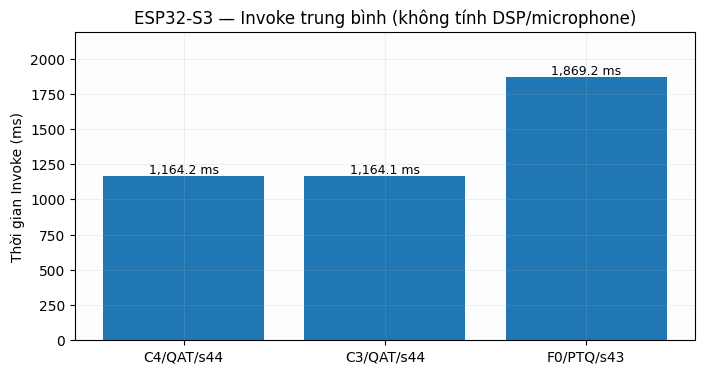

Đã lưu: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\D_Quantization\Full_24_Analysis\figures\D14_Invoke_Three_Static_Logs.png


In [37]:
# D14.2 — Đọc ba log Static Profiling, không yêu cầu chạy thêm model.
# Nếu mở notebook ngoài repository, dùng snapshot được kiểm tra từ log đính kèm; ghi nguồn minh bạch.
import re
from pathlib import Path

BOARD_BASELINES = [
    {'Tag':'C4/QAT/s44', 'Trial':'combo_pre0_mel40_fft2048__V1__s44',
     'Lượng tử':'QAT_INT8', 'Vai trò':'Nguyên mẫu (tắt pre)', 'α':0.0,
     'Model (B)':347968, 'Arena used (B)':169380, 'Arena allocated (B)':1048576,
     'Invoke avg (ms)':1164.2035, 'Số Invoke thành công':36,
     'Static correct':12, 'Static total':12, 'Nhãn parity':12,
     'INT8 exact':11, 'INT8 MAE (LSB)':5.083, 'INT8 maxerr (LSB)':61,
     'File log chuẩn':'C4_QAT.log', 'File log đính kèm':'C4_QAT(3).log'},
    {'Tag':'C3/QAT/s44', 'Trial':'combo_mel40_fft2048__V1__s44',
     'Lượng tử':'QAT_INT8', 'Vai trò':'Đối chứng bật pre', 'α':0.97,
     'Model (B)':347968, 'Arena used (B)':169380, 'Arena allocated (B)':1048576,
     'Invoke avg (ms)':1164.1082, 'Số Invoke thành công':36,
     'Static correct':11, 'Static total':12, 'Nhãn parity':12,
     'INT8 exact':7, 'INT8 MAE (LSB)':1.250, 'INT8 maxerr (LSB)':6,
     'File log chuẩn':'C3_QAT.log', 'File log đính kèm':'C3_QAT(3).log'},
    {'Tag':'F0/PTQ/s43', 'Trial':'F0__V1__s43',
     'Lượng tử':'PTQ_INT8', 'Vai trò':'Baseline lịch sử', 'α':0.97,
     'Model (B)':543976, 'Arena used (B)':268772, 'Arena allocated (B)':1048576,
     'Invoke avg (ms)':1869.1746, 'Số Invoke thành công':36,
     'Static correct':11, 'Static total':12, 'Nhãn parity':12,
     'INT8 exact':6, 'INT8 MAE (LSB)':3.250, 'INT8 maxerr (LSB)':26,
     'File log chuẩn':'F0_PTQ.log', 'File log đính kèm':'F0_PTQ(3).log'},
]

# Ưu tiên bản log đã copy cạnh notebook; các vị trí Deploy/Phase 4 chỉ là fallback.
def locate_log(row):
    here = Path.cwd().resolve()
    dirs = [LOCAL_LOG_DIR]
    for base in (here, *here.parents):
        dirs += [base, base / 'log', base / 'Log_Deploy',
                 base / 'Notebook' / '05_Quantization_Deployment' / 'log',
                 base / 'Frontend_Benchmarking' / 'Notebook' / '05_Quantization_Deployment' / 'log',
                 base / 'Experiments_Benchmarking' / 'Patient_Node' / 'Frontend_Benchmarking' / 'Notebook' / '05_Quantization_Deployment' / 'log',
                 base / 'Phase4_Deployment_Artifacts' / 'Log_Deploy',
                 base / 'AI_Training_Model' / 'Phase4_Deployment_Artifacts' / 'Log_Deploy']
    seen = set()
    for folder in dirs:
        if str(folder) in seen:
            continue
        seen.add(str(folder))
        for name in (row['File log đính kèm'], row['File log chuẩn']):
            p = folder / name
            if p.is_file():
                return p
    return None

def field(content, expression, name, cast=float):
    hit = re.search(expression, content, flags=re.M)
    if not hit:
        raise ValueError('Thiếu trường '+name+' trong log')
    return cast(hit.group(1))

def parse_board_log(content):
    out = {
        'Model (B)':field(content, r'Model Flash size\s*:\s*(\d+)\s*B', 'model size', int),
        'Arena used (B)':field(content, r'Tensor Arena used\s*:\s*(\d+)\s*B', 'arena used', int),
        'Arena allocated (B)':field(content, r'Tensor Arena capacity\s*:\s*(\d+)\s*B', 'arena capacity', int),
        'Invoke avg (ms)':field(content, r'Inference latency avg\s*:\s*[\d.]+\s*us\s*\(([\d.]+)\s*ms\)', 'latency avg'),
        'Số Invoke thành công':field(content, r'Inference count\s*:\s*(\d+)\s*OK', 'Invoke count', int),
        'Nhãn parity':field(content, r'Python/ESP32 label match\s*:\s*(\d+)/', 'label parity', int),
        'INT8 exact':field(content, r'Python/ESP32 INT8 exact\s*:\s*(\d+)/', 'INT8 exact', int),
        'INT8 MAE (LSB)':field(content, r'Python/ESP32 INT8 MAE\s*:\s*([\d.]+)\s*LSB', 'MAE'),
        'INT8 maxerr (LSB)':field(content, r'Python/ESP32 INT8 maxerr\s*:\s*(\d+)\s*LSB', 'maxerr', int),
    }
    static = re.search(r'Static sample accuracy\s*:\s*(\d+)/(\d+)', content)
    if not static:
        raise ValueError('Thiếu số mẫu static trong log')
    out['Static correct'], out['Static total'] = map(int, static.groups())
    if 'Operator compatibility   : PASS' not in content or 'Stability (3 rounds)     : PASS' not in content:
        raise ValueError('Log chưa PASS operator compatibility hoặc stability')
    return out

board_rows=[]
for item in BOARD_BASELINES:
    row=item.copy()
    path=locate_log(item)
    if path:
        content=path.read_text(encoding='utf-8', errors='replace')
        if item['Trial'] not in content or item['Lượng tử'] not in content:
            raise ValueError('Sai model/quantization trong '+str(path))
        try:
            row.update(parse_board_log(content))
            row['Nguồn']='ĐỌC LOG: '+str(path)
        except ValueError as exc:
            row['Nguồn']='SNAPSHOT xác minh; log cũ thiếu trường: '+str(exc)
            print('[CẢNH BÁO]',item['Tag'],row['Nguồn'])
    else:
        row['Nguồn']='SNAPSHOT đã xác minh: '+item['File log đính kèm']
    board_rows.append(row)

BOARD_STATIC_AUDIT = pd.DataFrame(board_rows)
assert len(BOARD_STATIC_AUDIT)==3
assert BOARD_STATIC_AUDIT['Nhãn parity'].eq(12).all()
assert BOARD_STATIC_AUDIT['Số Invoke thành công'].eq(36).all()
show_cols=['Tag','Vai trò','α','Model (B)','Arena used (B)','Arena allocated (B)',
           'Invoke avg (ms)','Static correct','Nhãn parity','INT8 exact','INT8 maxerr (LSB)','Nguồn']
display(BOARD_STATIC_AUDIT[show_cols])
BOARD_STATIC_AUDIT.to_csv(OUTPUT_DIR/'D14_Three_ESP32S3_Static_Logs.csv',
                          index=False,encoding='utf-8-sig')

f0=BOARD_STATIC_AUDIT.set_index('Tag').loc['F0/PTQ/s43']
c4=BOARD_STATIC_AUDIT.set_index('Tag').loc['C4/QAT/s44']
print(f'C4 vs F0: model giảm {(1-c4["Model (B)"]/f0["Model (B)"])*100:.1f}%; '
      f'arena used giảm {(1-c4["Arena used (B)"]/f0["Arena used (B)"])*100:.1f}%; '
      f'Invoke giảm {(1-c4["Invoke avg (ms)"]/f0["Invoke avg (ms)"])*100:.1f}%.')

fig,ax=plt.subplots(figsize=(8,4))
ax.bar(BOARD_STATIC_AUDIT['Tag'],BOARD_STATIC_AUDIT['Invoke avg (ms)'])
ax.set(title='ESP32-S3 — Invoke trung bình (không tính DSP/microphone)',
       ylabel='Thời gian Invoke (ms)')
for i, val in enumerate(BOARD_STATIC_AUDIT['Invoke avg (ms)']):
    ax.text(i, val+18, f'{val:,.1f} ms', ha='center', fontsize=9)
ax.set_ylim(0,BOARD_STATIC_AUDIT['Invoke avg (ms)'].max()*1.17)
save_show(fig,'D14_Invoke_Three_Static_Logs.png')


### D14.3 — Kết luận lượng tử hóa và triển khai tĩnh

Từ kết quả khảo sát **72 phiên bản lượng tử** và ba checkpoint kiểm thử trên ESP32-S3, nghiên cứu ưu tiên **V1/C4/s44/QAT INT8** làm ứng viên triển khai. Cấu hình này sử dụng `pre=0`, `Mel40`, `FFT2048`, đạt **Validation Accuracy 97,403%**, **historical Test Accuracy 95,597%**, **Asthma Recall 92,105%** và **FN/FP = 3/4**. Trong khi đó, F0/s43/PTQ đạt Test Accuracy 94,340% (FN/FP = 4/5), còn C3/s44/QAT đạt 91,195% (FN/FP = 5/9).

Trên ESP32-S3 (240 MHz), cả ba checkpoint đều thực hiện thành công **36/36 lần Invoke** và đạt **12/12 nhãn khớp** với kết quả Python trên tập tensor tĩnh. Riêng C4/s44/QAT sử dụng model **347.968 B**, TensorArena **169.380 B** và thời gian Invoke trung bình **1.164,20 ms**, giảm tương ứng khoảng **36,0%**, **37,0%** và **37,7%** so với F0/s43/PTQ. So với C3/s44/QAT, C4 có chi phí suy luận gần như tương đương nhưng đạt chất lượng phân loại tốt hơn trên historical Test.

Những kết quả này xác nhận **C4/s44/QAT INT8 là phương án khả thi và được ưu tiên trong phạm vi kiến trúc V1**, đồng thời cung cấp artifact tham chiếu cho bước kiểm chứng cuối.

---

### D14.4 — Giới hạn kiểm chứng và chuyển sang E

Các phép đo hiện tại mới đánh giá suy luận trên tensor tĩnh, chưa bao gồm thời gian tiền xử lý DSP và thu âm từ microphone. TensorArena được cấp phát **1 MiB PSRAM**, dù mức sử dụng thực tế của C4 là 169.380 B. Ngoài ra, C4 vẫn có sai khác raw INT8 tối đa **61 LSB** ở một mẫu, dù nhãn dự đoán không thay đổi. Kết quả historical Test cũng chưa chứng minh khả năng tổng quát hóa trên dữ liệu bệnh nhân mới.

**Kết thúc D**, nghiên cứu giữ **V1/C4/s44/QAT INT8** làm ứng viên tham chiếu sau lượng tử hóa và kiểm thử tĩnh, không mở rộng thêm vòng profiling Front-End.

Bước tiếp theo là **E — Kiểm chứng cuối: Front-End, kiến trúc và lựa chọn mô hình triển khai**. Khi đã cố định cấu hình C4 và seed 44, nghiên cứu tiếp tục xem xét kiến trúc V1 so với V3 dựa trên chất lượng phân loại, kích thước model, bộ nhớ và thời gian suy luận thực tế. Kết quả tại E sẽ là cơ sở đưa ra **quyết định lựa chọn mô hình triển khai cuối cùng**.

## **Câu hỏi:** Tại sao mô hình QAT INT8 có thể đạt Accuracy cao hơn FP32 trong khi độ chính xác biểu diễn số giảm từ 32 bit xuống 8 bit?

Việc giảm độ chính xác biểu diễn số không đồng nghĩa với việc Accuracy phân loại bắt buộc giảm.

Trong nghiên cứu này, PTQ thực hiện lượng tử hóa sau huấn luyện mà không cập nhật trọng số, trong khi QAT tiếp tục fine-tuning từ checkpoint FP32 với cơ chế mô phỏng sai số lượng tử hóa. Quá trình này cho phép mô hình điều chỉnh trọng số và ranh giới quyết định để thích nghi với biểu diễn INT8.

Trên 24 checkpoint khảo sát, QAT INT8 đạt Accuracy trung bình trên historical Test là 91,54%, cao hơn FP32 là 90,54%, trong khi Accuracy trung bình trên Validation gần tương đương, lần lượt là 97,24% và 97,35%. Cả ba phương pháp đều được đánh giá với ngưỡng phân loại cố định 0,5.

Kết quả này cho thấy QAT có khả năng duy trì hiệu năng và trong một số trường hợp còn cải thiện kết quả phân loại sau lượng tử hóa. Tuy nhiên, nhóm không khẳng định INT8 ưu việt hơn FP32 về khả năng biểu diễn hay toàn bộ cải thiện đến từ riêng kỹ thuật lượng tử hóa, bởi quá trình fine-tuning cũng có thể đóng góp vào sự thay đổi hiệu năng.

Giá trị chính của kết quả là mô hình INT8 đạt chất lượng phân loại cạnh tranh với FP32 trong khi giảm đáng kể nhu cầu lưu trữ, tạo điều kiện triển khai thực tế trên ESP32-S3.